# Waste Material Image Classification — Archived Team Experiment

This notebook preserves the team coursework code and experiment outputs. Large repetitive embedded Grad-CAM galleries were removed for repository viewing; curated original output visuals appear in `figures/`. No model was retrained for repository preparation. The dataset folder `trash_images/` is not distributed.


# Data Prepocessing

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras import layers

Bagian ini mengimpor library yang dibutuhkan. os, zipfile, dan Path digunakan untuk membaca struktur folder dataset. pandas digunakan untuk membuat dataframe berisi path gambar dan label. train_test_split digunakan agar pembagian data lebih rapi dan bisa dibuat stratified. tensorflow digunakan untuk membuat pipeline preprocessing gambar.

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

Seed digunakan agar hasil splitting, shuffle, dan training lebih konsisten setiap kali notebook dijalankan

In [ ]:
dataset_dir = Path("trash_images")

print("Folder dataset:", dataset_dir)

Folder dataset: trash_images


In [ ]:
print("Folder dataset:", dataset_dir)
print("Isi folder utama:")

for item in dataset_dir.iterdir():
    print(item.name)

Folder dataset: trash_images
Isi folder utama:
cardboard
glass
metal
paper
plastic
trash


In [ ]:
image_paths = []
labels = []

valid_extensions = [".jpg", ".jpeg", ".png"]

for class_folder in dataset_dir.iterdir():
    if class_folder.is_dir():
        class_name = class_folder.name
        
        for image_file in class_folder.iterdir():
            if image_file.suffix.lower() in valid_extensions:
                image_paths.append(str(image_file))
                labels.append(class_name)

df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

df.head()

,image_path,label
0,trash_images\cardboard\cardboard_001.jpg,cardboard
1,trash_images\cardboard\cardboard_002.jpg,cardboard
2,trash_images\cardboard\cardboard_003.jpg,cardboard
3,trash_images\cardboard\cardboard_004.jpg,cardboard
4,trash_images\cardboard\cardboard_005.jpg,cardboard


In [ ]:
print("Total gambar:", len(df))
print("Jumlah kelas:", df["label"].nunique())
print("Nama kelas:", sorted(df["label"].unique()))

Total gambar: 2527
Jumlah kelas: 6
Nama kelas: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


Kode ini digunakan untuk memastikan jumlah total gambar dan jumlah kelas. Untuk dataset ini, kelasnya adalah:

cardboard, glass, metal, paper, plastic, trash

Karena jumlah kelas lebih dari 2 dan setiap gambar hanya punya satu label, maka problem ini termasuk multi-class image classification.

label
paper        594
glass        501
plastic      482
metal        410
cardboard    403
trash        137
Name: count, dtype: int64


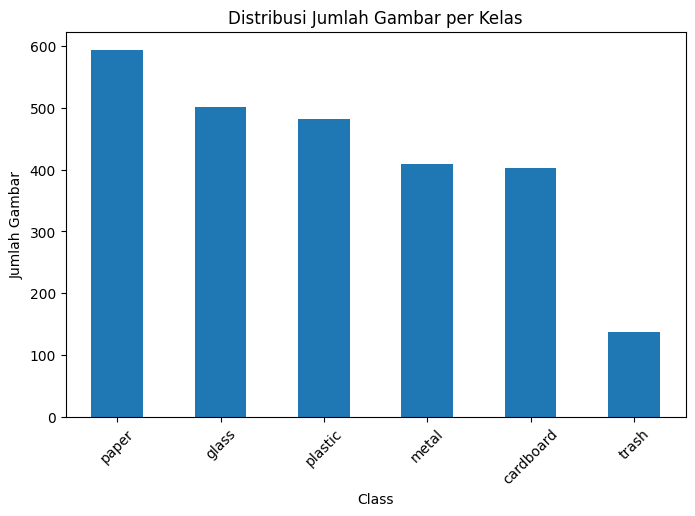

In [ ]:
class_distribution = df["label"].value_counts()
print(class_distribution)

plt.figure(figsize=(8, 5))
class_distribution.plot(kind="bar")
plt.title("Distribusi Jumlah Gambar per Kelas")
plt.xlabel("Class")
plt.ylabel("Jumlah Gambar")
plt.xticks(rotation=45)
plt.show()

Bagian ini mengecek apakah dataset seimbang atau tidak. Pada dataset ini, kelas seperti paper, glass, dan plastic memiliki jumlah gambar lebih banyak, sedangkan kelas trash jauh lebih sedikit.

Ini menunjukkan adanya class imbalance. Dampaknya, model bisa cenderung lebih bagus memprediksi kelas mayoritas dan lebih lemah pada kelas minoritas.

In [ ]:
class_names = sorted(df["label"].unique())

class_to_index = {
    class_name: index for index, class_name in enumerate(class_names)
}

index_to_class = {
    index: class_name for class_name, index in class_to_index.items()
}

df["label_index"] = df["label"].map(class_to_index)

print("Class to index:")
print(class_to_index)

df.head()

Class to index:
{'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}


,image_path,label,label_index
0,trash_images\cardboard\cardboard_001.jpg,cardboard,0
1,trash_images\cardboard\cardboard_002.jpg,cardboard,0
2,trash_images\cardboard\cardboard_003.jpg,cardboard,0
3,trash_images\cardboard\cardboard_004.jpg,cardboard,0
4,trash_images\cardboard\cardboard_005.jpg,cardboard,0


Pada tahap ini, label kategori yang awalnya berbentuk teks diubah menjadi angka. Hal ini perlu dilakukan karena model deep learning tidak dapat langsung memproses label berbentuk string seperti `cardboard`, `glass`, `metal`, `paper`, `plastic`, dan `trash`.

Pertama, seluruh nama kelas diambil dari kolom `label` kemudian diurutkan menggunakan fungsi `sorted()`. Setelah itu dibuat dictionary `class_to_index` untuk memetakan setiap nama kelas menjadi angka. Sebaliknya, dictionary `index_to_class` juga dibuat untuk mengubah kembali angka prediksi model menjadi nama kelas aslinya.

Mapping label yang dihasilkan adalah:

```text
cardboard = 0
glass     = 1
metal     = 2
paper     = 3
plastic   = 4
trash     = 5

## Split Data

In [ ]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label_index"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_index"],
    random_state=SEED
)

print("Jumlah train data:", len(train_df))
print("Jumlah validation data:", len(val_df))
print("Jumlah test data:", len(test_df))

Jumlah train data: 1768
Jumlah validation data: 379
Jumlah test data: 380


Setelah label dikonversi menjadi angka, dataset kemudian dibagi menjadi training, validation, dan testing set. Data splitting dilakukan dengan rasio 70:15:15. Rasio ini dipilih karena jumlah data relatif terbatas, sehingga sebagian besar data digunakan untuk training, tetapi validation dan testing set tetap disediakan untuk mengevaluasi kemampuan generalisasi model.

Proses splitting dilakukan dalam dua tahap. Pertama, dataset dibagi menjadi 70% training set dan 30% temporary set. Selanjutnya, temporary set dibagi lagi menjadi validation set dan testing set dengan rasio 50:50. Dengan demikian, validation set dan testing set masing-masing berjumlah sekitar 15% dari keseluruhan dataset.

Splitting dilakukan secara stratified menggunakan parameter `stratify`. Tujuannya adalah menjaga proporsi setiap kelas agar tetap seimbang pada masing-masing subset. Teknik ini penting karena distribusi gambar pada dataset tidak sepenuhnya seimbang. Jika splitting dilakukan secara random tanpa stratification, terdapat risiko beberapa kelas minoritas memiliki jumlah data yang terlalu sedikit pada validation atau testing set.

Hasil pembagian data adalah:

```text
Training data   : 1768 gambar
Validation data : 379 gambar
Testing data    : 380 gambar

In [ ]:
print("Distribusi train:")
print(train_df["label"].value_counts())

print("\nDistribusi validation:")
print(val_df["label"].value_counts())

print("\nDistribusi test:")
print(test_df["label"].value_counts())

Distribusi train:
label
paper        416
glass        350
plastic      337
metal        287
cardboard    282
trash         96
Name: count, dtype: int64

Distribusi validation:
label
paper        89
glass        75
plastic      72
cardboard    61
metal        61
trash        21
Name: count, dtype: int64

Distribusi test:
label
paper        89
glass        76
plastic      73
metal        62
cardboard    60
trash        20
Name: count, dtype: int64


Setelah dataset dibagi menjadi training set, validation set, dan testing set, distribusi kelas pada setiap subset dicek kembali. Tujuannya adalah untuk memastikan bahwa semua kelas tetap muncul pada setiap subset dan proporsinya tidak berubah terlalu jauh dari dataset asli.

Hasil output menunjukkan bahwa training set berisi 1768 gambar, validation set berisi 379 gambar, dan testing set berisi 380 gambar. Semua kelas, yaitu `cardboard`, `glass`, `metal`, `paper`, `plastic`, dan `trash`, tetap muncul pada ketiga subset tersebut.

Distribusi ini menunjukkan bahwa proses stratified split berjalan dengan baik karena proporsi kelas tetap terjaga. Namun, dataset masih memiliki class imbalance karena kelas `paper`, `glass`, dan `plastic` memiliki jumlah gambar lebih banyak dibandingkan kelas `trash`. Oleh karena itu, class weight akan digunakan pada tahap training agar model tidak terlalu bias terhadap kelas mayoritas.

In [ ]:

# KONFIGURASI IMAGE PREPROCESSING

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)

Image size: (224, 224)
Batch size: 32
Number of classes: 6


Pada tahap ini, konfigurasi utama untuk preprocessing gambar ditentukan. Ukuran gambar ditetapkan menjadi 224 × 224 piksel, batch size ditetapkan sebesar 32, dan jumlah kelas dihitung secara otomatis dari dataset.

Ukuran 224 × 224 digunakan agar seluruh gambar memiliki dimensi input yang sama sebelum masuk ke model CNN. Batch size 32 digunakan agar model memproses 32 gambar dalam satu batch sehingga training menjadi lebih stabil dan efisien. Jumlah kelas pada dataset adalah 6, yaitu `cardboard`, `glass`, `metal`, `paper`, `plastic`, dan `trash`.

Selain itu, `tf.data.AUTOTUNE` digunakan untuk membantu TensorFlow mengoptimalkan proses loading dan preprocessing data. Dengan konfigurasi ini, data sudah siap untuk masuk ke tahap berikutnya, yaitu membaca gambar, resizing, normalisasi pixel, dan pembuatan TensorFlow dataset pipeline.

In [ ]:

# FUNGSI UNTUK MEMBACA DAN MEMPROSES GAMBAR


def load_and_preprocess_image(image_path, label):
    image = tf.io.read_file(image_path)
    
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    
    image.set_shape([None, None, 3])
    
    image = tf.image.resize(
        image,
        IMG_SIZE
    )
    
    image = tf.cast(image, tf.float32) / 255.0
    
    label = tf.one_hot(
        label,
        depth=NUM_CLASSES
    )
    
    return image, label

Pada tahap ini dibuat fungsi `load_and_preprocess_image()` untuk membaca gambar dari path yang ada di dataframe. Gambar dibaca menggunakan `tf.io.read_file()`, lalu didecode dengan `tf.image.decode_image()` agar bisa membaca beberapa format gambar seperti JPG, JPEG, dan PNG. Setelah itu, gambar diubah ukurannya menjadi 224 × 224 piksel supaya semua input memiliki ukuran yang sama saat masuk ke model CNN.

Setelah proses resize, nilai pixel gambar dinormalisasi dari rentang 0–255 menjadi 0–1 dengan cara membagi nilai pixel dengan 255. Normalisasi ini penting agar proses training menjadi lebih stabil. Label juga diubah menjadi bentuk one-hot encoding menggunakan `tf.one_hot()` karena model menggunakan output `softmax` untuk klasifikasi 6 kelas.

In [ ]:
# MEMBUAT TF.DATA DATASET - VERSI LEBIH RAPI


def create_dataset(dataframe, shuffle=False, use_cache=True):
    image_paths = dataframe["image_path"].values
    labels = dataframe["label_index"].values
    
    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )
    
    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=AUTOTUNE
    )
    
    if use_cache:
        dataset = dataset.cache()
    
    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )
    
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)
    
    return dataset


train_ds = create_dataset(train_df, shuffle=True, use_cache=True)
val_ds = create_dataset(val_df, shuffle=False, use_cache=True)
test_ds = create_dataset(test_df, shuffle=False, use_cache=True)

Pada tahap ini dataframe diubah menjadi TensorFlow dataset menggunakan `tf.data.Dataset.from_tensor_slices()`. Data yang digunakan adalah path gambar dan label numerik. Setiap gambar kemudian diproses menggunakan fungsi `load_and_preprocess_image()` yang sudah dibuat sebelumnya.

Pipeline ini juga menggunakan `cache()`, `shuffle()`, `batch()`, dan `prefetch()`. `cache()` digunakan agar proses loading data lebih cepat, `shuffle()` digunakan pada training set agar data tidak dipelajari berdasarkan urutan tertentu, `batch()` digunakan agar model memproses 32 gambar sekaligus, dan `prefetch()` digunakan untuk membuat proses training lebih efisien. Hasil akhirnya adalah tiga dataset siap pakai, yaitu `train_ds`, `val_ds`, dan `test_ds`.

## Data Augmentation

In [ ]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.05),
    layers.RandomTranslation(0.03, 0.03),
    layers.RandomContrast(0.08)
], name="data_augmentation")

Pada tahap ini dibuat layer `data_augmentation` untuk menambahkan variasi pada gambar training. Augmentation dilakukan dengan beberapa transformasi seperti horizontal flip, rotation, zoom, translation, dan contrast adjustment. Tujuan utama dari data augmentation adalah agar model tidak hanya menghafal gambar training, tetapi mampu mengenali objek dalam berbagai kondisi, seperti posisi sedikit bergeser, objek sedikit miring, ukuran berubah, atau pencahayaan berbeda.

Sebelum mendapatkan konfigurasi final, beberapa kombinasi parameter augmentation sempat dicoba. Pada percobaan awal, nilai rotation, zoom, dan translation dibuat lebih besar. Hasil visualisasi menunjukkan bahwa gambar memang memiliki variasi lebih banyak, tetapi beberapa gambar menjadi terlalu blur, muncul distortion pada bagian pinggir, dan detail objek mulai berkurang. Hal ini kurang ideal karena CNN membutuhkan informasi visual seperti edge, texture, contour, dan bentuk objek untuk belajar dengan baik.

Setelah itu, parameter augmentation dikurangi secara bertahap agar transformasi tetap realistis. Nilai rotation dikurangi agar objek tidak terlalu miring, zoom dikurangi agar objek tidak terlalu terpotong, dan translation dikurangi agar posisi objek tidak terlalu bergeser keluar frame. Contrast juga dibuat moderat agar pencahayaan berubah tetapi tidak merusak warna asli gambar.

Konfigurasi final yang digunakan adalah `RandomFlip("horizontal")`, `RandomRotation(0.05)`, `RandomZoom(0.05)`, `RandomTranslation(0.03, 0.03)`, dan `RandomContrast(0.08)`. Konfigurasi ini dipilih karena hasil visualisasinya paling stabil: objek masih terlihat jelas, tidak terlalu blur, tidak memiliki distortion yang mengganggu, dan tetap memberikan variasi yang cukup untuk training.

Dengan konfigurasi final ini, augmentation dianggap sesuai untuk dataset klasifikasi sampah karena mampu menambah variasi gambar tanpa merusak identitas objek utama. Augmentation hanya diterapkan pada training data, sedangkan validation dan testing tetap menggunakan gambar asli agar evaluasi model tetap adil.

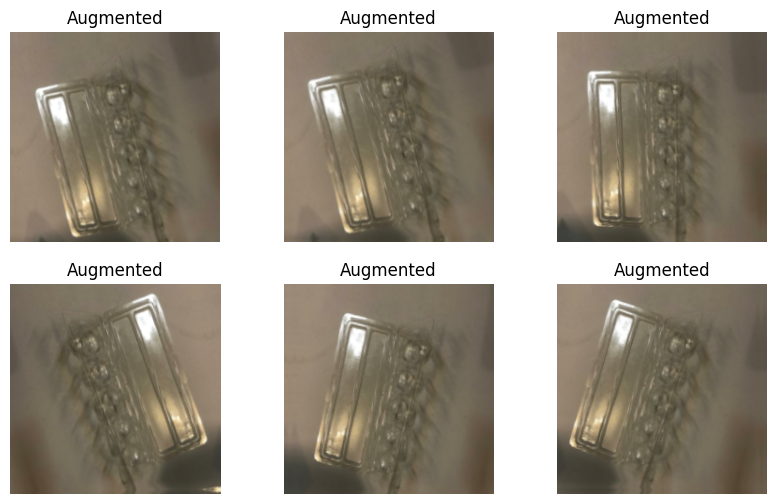

In [86]:
# ============================================================
# 15. VISUALISASI CONTOH AUGMENTATION
# ============================================================

for images, labels in train_ds.take(1):
    sample_image = images[0]
    
    plt.figure(figsize=(10, 6))
    
    for i in range(6):
        augmented_image = data_augmentation(
            tf.expand_dims(sample_image, axis=0),
            training=True
        )
        
        augmented_image = tf.clip_by_value(
            tf.squeeze(augmented_image),
            0.0,
            1.0
        )
        
        plt.subplot(2, 3, i + 1)
        plt.imshow(augmented_image)
        plt.axis("off")
        plt.title("Augmented")
    
    plt.show()

Pada tahap ini dilakukan visualisasi hasil augmentation untuk memastikan bahwa transformasi yang diterapkan masih masuk akal. Satu gambar dari training set dipilih, kemudian diberikan augmentation beberapa kali sehingga menghasilkan beberapa versi gambar yang berbeda.

Dari hasil output, objek utama masih dapat dikenali dengan jelas meskipun mengalami sedikit perubahan posisi, rotasi, zoom, dan kontras. Hal ini menunjukkan bahwa konfigurasi augmentation final sudah cukup baik karena memberikan variasi tanpa merusak bentuk dan detail utama objek.

Visualisasi ini penting dilakukan sebelum training karena augmentation yang terlalu agresif dapat membuat gambar menjadi tidak realistis dan justru menurunkan performa model. Berdasarkan hasil visualisasi, konfigurasi augmentation final dinilai layak digunakan untuk membantu model menjadi lebih robust, meningkatkan kemampuan generalisasi, dan mengurangi risiko overfitting.

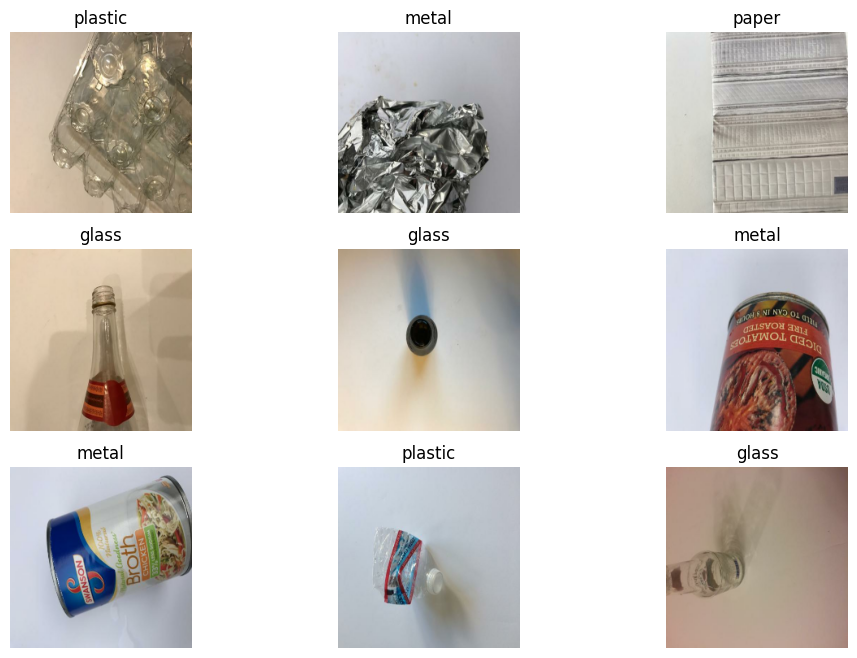

In [87]:
# ============================================================
# 16. VISUALISASI CONTOH GAMBAR DARI DATASET
# ============================================================

plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(9):
        image = images[i]
        label_index = np.argmax(labels[i].numpy())
        label_name = index_to_class[label_index]
        
        plt.subplot(3, 3, i + 1)
        plt.imshow(image)
        plt.title(label_name)
        plt.axis("off")

plt.show()

Pada tahap ini dilakukan visualisasi beberapa contoh gambar dari training set untuk memastikan bahwa data sudah terbaca dengan benar. Gambar ditampilkan bersama labelnya, seperti `plastic`, `metal`, `paper`, dan `glass`.

Visualisasi ini penting karena sebelum model dilatih, kita perlu memastikan bahwa gambar dan label sudah sesuai. Jika gambar yang ditampilkan tidak cocok dengan labelnya, maka model dapat belajar dari data yang salah. Berdasarkan output, gambar berhasil ditampilkan dengan label yang sesuai, sehingga dataset dapat digunakan untuk tahap training model.

Selain itu, visualisasi ini juga membantu memahami karakteristik dataset. Beberapa kelas terlihat memiliki bentuk dan tekstur yang cukup berbeda, tetapi ada juga kelas yang secara visual bisa mirip, misalnya `glass`, `plastic`, dan `metal`. Hal ini dapat menjadi tantangan bagi model saat melakukan klasifikasi.

## Class Weight

In [ ]:
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_df["label_index"]),
    y=train_df["label_index"]
)

class_weights = {
    i: float(weight) for i, weight in enumerate(class_weights_array)
}

print("Class weights:")
print(class_weights)

Class weights:
{0: 1.044917257683215, 1: 0.8419047619047619, 2: 1.0267131242740999, 3: 0.7083333333333334, 4: 0.874381800197824, 5: 3.0694444444444446}


Pada tahap ini dilakukan perhitungan class weight untuk menangani masalah class imbalance. Class imbalance terjadi karena jumlah gambar pada setiap kelas tidak sama. Pada dataset ini, kelas seperti `paper`, `glass`, dan `plastic` memiliki jumlah data lebih banyak, sedangkan kelas `trash` memiliki jumlah data paling sedikit.

Class weight dihitung menggunakan `compute_class_weight()` dengan mode `balanced`. Tujuannya adalah agar kelas dengan jumlah data lebih sedikit mendapatkan bobot yang lebih besar saat training. Dengan begitu, model tidak terlalu bias terhadap kelas mayoritas dan tetap memperhatikan kelas minoritas.

Hasil class weight menunjukkan bahwa kelas `trash` mendapatkan bobot paling besar, yaitu sekitar `3.06`. Hal ini masuk akal karena kelas `trash` memiliki jumlah data paling sedikit. Sebaliknya, kelas `paper` mendapatkan bobot paling kecil, yaitu sekitar `0.71`, karena jumlah datanya paling banyak.

Class weight ini nantinya digunakan pada saat `model.fit()` agar kesalahan pada kelas minoritas memiliki pengaruh loss yang lebih besar. Dengan cara ini, model diharapkan dapat belajar lebih seimbang pada seluruh kelas, bukan hanya pada kelas yang jumlah datanya banyak.

In [ ]:
# CUSTOM CLASS WEIGHT UNTUK MENINGKATKAN RECALL GLASS


custom_class_weights = class_weights.copy()

print("Class mapping:")
print(class_to_index)

glass_index = class_to_index["glass"]

custom_class_weights[glass_index] = 1.3

print("Original class weights:")
print(class_weights)

print("\nCustom class weights:")
print(custom_class_weights)

Class mapping:
{'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}
Original class weights:
{0: 1.044917257683215, 1: 0.8419047619047619, 2: 1.0267131242740999, 3: 0.7083333333333334, 4: 0.874381800197824, 5: 3.0694444444444446}

Custom class weights:
{0: 1.044917257683215, 1: 1.3, 2: 1.0267131242740999, 3: 0.7083333333333334, 4: 0.874381800197824, 5: 3.0694444444444446}


Setelah class weight awal dihitung, dilakukan penyesuaian tambahan pada kelas `glass`. Penyesuaian ini dilakukan karena dari hasil evaluasi sebelumnya, kelas `glass` memiliki recall yang rendah, sehingga model masih sering salah mengenali gambar kaca sebagai kelas lain seperti `metal`, `plastic`, atau `trash`.

Pada tahap ini, class weight awal disalin terlebih dahulu ke dalam variabel `custom_class_weights`. Setelah itu, indeks untuk kelas `glass` diambil dari `class_to_index`, yaitu `glass = 1`. Bobot kelas `glass` kemudian dinaikkan secara manual menjadi `1.3`.

Tujuan dari peningkatan bobot ini adalah agar model memberikan perhatian lebih besar terhadap kelas `glass` selama training. Jika model salah memprediksi gambar `glass`, loss yang dihasilkan akan menjadi lebih besar dibanding sebelumnya. Dengan begitu, model diharapkan dapat belajar lebih baik dalam mengenali karakteristik visual kelas `glass`.

Berdasarkan output, class weight awal untuk `glass` adalah sekitar `0.84`, kemudian dinaikkan menjadi `1.3` pada custom class weight. Perubahan ini tidak mengubah bobot kelas lain, sehingga penyesuaian hanya difokuskan pada kelas `glass`.

In [90]:
# ============================================================
# 18. CEK SHAPE DATASET
# ============================================================

for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 6)


Pada tahap ini dilakukan pengecekan shape dari data yang sudah masuk ke TensorFlow dataset pipeline. Pengecekan ini penting untuk memastikan bahwa format gambar dan label sudah sesuai sebelum digunakan untuk training model CNN.

# MODELLING

In [ ]:

# IMPORT LIBRARY TAMBAHAN UNTUK MODELING DAN EVALUATION


import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [ ]:


def get_callbacks(model_name):
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            mode="max",
            patience=12,
            restore_best_weights=True,
            verbose=1
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_accuracy",
            mode="max",
            factor=0.5,
            patience=5,
            min_lr=1e-7,
            verbose=1
        ),

        tf.keras.callbacks.ModelCheckpoint(
            filepath=f"best_{model_name}.keras",
            monitor="val_accuracy",
            mode="max",
            save_best_only=True,
            verbose=1
        )
    ]
    
    return callbacks

## Callback untuk Improved CNN dengan Custom Class Weight

Pada tahap ini digunakan callback untuk membantu proses training model Improved CNN agar lebih stabil dan tidak overfitting. Callback yang digunakan terdiri dari `EarlyStopping`, `ReduceLROnPlateau`, dan `ModelCheckpoint`.

`EarlyStopping` digunakan untuk menghentikan training secara otomatis jika performa validation tidak mengalami peningkatan dalam beberapa epoch. Pada model ini, parameter yang dipantau adalah `val_accuracy` dengan `mode="max"`, karena tujuan utama training adalah meningkatkan akurasi validasi. Nilai `patience=12` diberikan agar model memiliki waktu yang cukup untuk belajar, terutama karena model menggunakan custom class weight untuk meningkatkan recall kelas `glass`. Selain itu, `restore_best_weights=True` digunakan agar model dikembalikan ke bobot terbaik setelah training selesai.

`ReduceLROnPlateau` digunakan untuk menurunkan learning rate ketika `val_accuracy` tidak meningkat selama beberapa epoch. Dengan `factor=0.5`, learning rate akan dikurangi setengahnya agar proses update bobot menjadi lebih kecil dan lebih halus. Hal ini membantu model mencari solusi yang lebih baik ketika performa validation mulai stagnan.

`ModelCheckpoint` digunakan untuk menyimpan model terbaik selama training. Model hanya akan disimpan ketika `val_accuracy` meningkat, sehingga file yang tersimpan merupakan model dengan performa validation terbaik. Nama file disesuaikan dengan `model_name`, sehingga setiap model memiliki checkpoint masing-masing.

Callback ini dipilih karena pada percobaan sebelumnya, ketika menggunakan `val_loss` sebagai monitor, model berhenti terlalu cepat dan kembali ke epoch awal meskipun validation accuracy sebenarnya masih berpotensi meningkat. Oleh karena itu, pada eksperimen ini digunakan `val_accuracy` sebagai monitor utama agar training lebih fokus pada peningkatan performa klasifikasi.

In [ ]:
# ============================================================
# MODEL 1: BASELINE CNN
# ============================================================

def build_baseline_cnn():
    model = models.Sequential([
        layers.Input(shape=(224, 224, 3)),

        data_augmentation,

        layers.Conv2D(
            filters=32,
            kernel_size=(3, 3),
            activation="relu",
            padding="same"
        ),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.Conv2D(
            filters=64,
            kernel_size=(3, 3),
            activation="relu",
            padding="same"
        ),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.Conv2D(
            filters=128,
            kernel_size=(3, 3),
            activation="relu",
            padding="same",
            name="baseline_last_conv_layer"
        ),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.Flatten(),

        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),

        layers.Dense(NUM_CLASSES, activation="softmax")
    ])
    
    return model


baseline_model = build_baseline_cnn()

baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

baseline_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ baseline_last_conv_layer        │ (None, 56, 56, 128)    │        73,856 │
│ (Conv2D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,939,206 (49.36 MB)

 Trainable params: 12,939,206 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

## 21. Model 1: Baseline CNN

Pada tahap ini dibuat model pertama, yaitu **Baseline CNN**. Model ini digunakan sebagai model awal atau pembanding dasar sebelum membuat model yang lebih kompleks. Baseline model penting karena dapat menjadi acuan untuk melihat apakah modifikasi model berikutnya benar-benar memberikan peningkatan performa atau tidak.

Model ini menggunakan arsitektur CNN sederhana yang terdiri dari beberapa layer utama, yaitu `Input`, `Data Augmentation`, `Conv2D`, `MaxPooling2D`, `Flatten`, `Dense`, `Dropout`, dan output layer `Softmax`.

---

### Input Layer

Model diawali dengan:

`layers.Input(shape=(224, 224, 3))`

Bagian ini menentukan bentuk input gambar yang akan masuk ke model. Ukuran gambar adalah 224 × 224 piksel dengan 3 channel warna RGB. Ukuran ini sesuai dengan preprocessing sebelumnya, di mana semua gambar sudah di-resize menjadi 224 × 224.

---

### Data Augmentation

Setelah input layer, digunakan:

`data_augmentation`

Data augmentation digunakan agar model melihat variasi gambar selama training. Gambar dapat mengalami perubahan kecil seperti flip, rotation, zoom, translation, dan contrast. Tujuannya adalah agar model tidak hanya menghafal gambar training, tetapi mampu mengenali objek dalam kondisi yang berbeda. Augmentation ini membantu mengurangi risiko overfitting.

---

### Convolutional Layer

Model menggunakan tiga convolutional layer dengan jumlah filter 32, 64, dan 128.

Layer pertama:

`Conv2D(filters=32, kernel_size=(3,3), activation="relu", padding="same")`

Layer kedua:

`Conv2D(filters=64, kernel_size=(3,3), activation="relu", padding="same")`

Layer ketiga:

`Conv2D(filters=128, kernel_size=(3,3), activation="relu", padding="same")`

Convolutional layer digunakan untuk mengekstraksi fitur dari gambar. Pada layer awal, model biasanya belajar fitur sederhana seperti garis, tepi, warna, dan tekstur dasar. Pada layer yang lebih dalam, model mulai belajar fitur yang lebih kompleks seperti bentuk objek dan pola visual dari masing-masing kelas sampah.

Jumlah filter dibuat bertahap dari 32 ke 64 lalu 128 karena semakin dalam layer CNN, semakin kompleks fitur yang perlu dipelajari. Filter 32 digunakan pada awal model agar komputasi masih ringan. Filter 64 dan 128 digunakan pada layer berikutnya agar model memiliki kapasitas lebih besar untuk menangkap pola visual yang lebih kompleks.

---

### Kernel Size 3 × 3

Setiap convolutional layer menggunakan:

`kernel_size=(3, 3)`

Kernel 3 × 3 umum digunakan pada CNN karena cukup efektif untuk menangkap fitur lokal pada gambar, seperti edge, corner, dan texture. Ukuran ini juga lebih ringan dibanding kernel yang lebih besar, sehingga cocok untuk baseline model.

---

### Padding Same

Model menggunakan:

`padding="same"`

Padding ini membuat ukuran feature map tetap lebih terjaga setelah proses convolution. Dengan `padding="same"`, informasi di bagian tepi gambar tidak langsung hilang. Hal ini penting karena objek pada gambar bisa berada tidak selalu tepat di tengah.

---

### Activation Function ReLU

Setiap convolutional layer menggunakan activation function:

`activation="relu"`

ReLU digunakan karena cocok untuk hidden layer pada CNN. ReLU membantu model belajar pola non-linear pada gambar, seperti bentuk, tekstur, dan perbedaan warna. Tanpa activation function, model hanya akan menjadi kombinasi operasi linear dan sulit mempelajari pola kompleks.

ReLU juga lebih efisien dibanding sigmoid atau tanh karena perhitungannya sederhana dan membantu mengurangi masalah vanishing gradient. Oleh karena itu, ReLU menjadi pilihan umum untuk hidden layer pada image classification.

---

### MaxPooling Layer

Setelah setiap convolutional layer, digunakan:

`MaxPooling2D(pool_size=(2,2))`

MaxPooling digunakan untuk mengurangi ukuran feature map. Dengan ukuran pool 2 × 2, dimensi feature map akan diperkecil sehingga jumlah komputasi menjadi lebih ringan.

Selain itu, MaxPooling membantu model mengambil fitur paling penting dari feature map. Teknik ini juga membuat model lebih tahan terhadap perubahan kecil pada posisi objek. Misalnya, jika botol atau kertas sedikit bergeser dalam gambar, model tetap dapat mengenalinya.

---

### Last Convolution Layer

Pada convolutional layer terakhir diberikan nama:

`name="baseline_last_conv_layer"`

Nama ini penting karena nantinya dapat digunakan untuk visualisasi attention map atau Grad-CAM. Grad-CAM membutuhkan layer convolution terakhir untuk melihat area gambar mana yang paling diperhatikan model saat membuat prediksi.

---

### Flatten Layer

Setelah proses convolution dan pooling selesai, digunakan:

`layers.Flatten()`

Flatten digunakan untuk mengubah feature map multidimensi menjadi vector satu dimensi. Vector ini kemudian dikirim ke dense layer untuk proses klasifikasi.

Pada baseline model, `Flatten()` digunakan karena sederhana dan umum dipakai pada CNN dasar. Namun, kelemahannya adalah jumlah parameter bisa menjadi cukup besar sehingga model lebih rentan terhadap overfitting. Karena itu, pada model improved nanti dapat digunakan alternatif seperti `GlobalAveragePooling2D()`.

---

### Dense Layer

Setelah Flatten, digunakan:

`layers.Dense(128, activation="relu")`

Dense layer berfungsi untuk mempelajari kombinasi fitur yang sudah diekstraksi oleh convolutional layer. Jumlah neuron 128 dipilih karena cukup untuk baseline model: tidak terlalu kecil sehingga model masih bisa belajar pola, tetapi juga tidak terlalu besar agar risiko overfitting tidak terlalu tinggi.

Activation ReLU tetap digunakan pada dense layer karena layer ini masih termasuk hidden layer. ReLU membantu model mempelajari hubungan non-linear dari fitur-fitur gambar sebelum masuk ke output layer.

---

### Dropout Layer

Model menggunakan:

`layers.Dropout(0.4)`

Dropout digunakan untuk mengurangi overfitting. Nilai 0.4 berarti selama training, 40% neuron pada layer tersebut akan dimatikan secara acak. Dengan cara ini, model tidak terlalu bergantung pada neuron tertentu dan dapat belajar representasi yang lebih general.

Dropout penting pada baseline CNN karena model menggunakan Flatten, yang dapat menghasilkan banyak parameter. Dengan Dropout, risiko model menghafal data training dapat dikurangi.

---

### Output Layer Softmax

Output layer menggunakan:

`layers.Dense(NUM_CLASSES, activation="softmax")`

Karena dataset memiliki 6 kelas, maka `NUM_CLASSES = 6`. Output layer memiliki 6 neuron, masing-masing mewakili satu kelas, yaitu `cardboard`, `glass`, `metal`, `paper`, `plastic`, dan `trash`.

Activation function yang digunakan adalah `softmax` karena masalah ini merupakan **multi-class classification**, di mana satu gambar hanya termasuk ke dalam satu kelas. Softmax mengubah output model menjadi probabilitas untuk setiap kelas. Kelas dengan probabilitas tertinggi akan menjadi hasil prediksi model.

---

### Compile Model

Model dikompilasi menggunakan optimizer Adam:

`optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4)`

Adam dipilih karena stabil dan umum digunakan untuk deep learning. Learning rate 1e-4 digunakan agar proses training lebih hati-hati dan tidak terlalu agresif.

Loss function yang digunakan adalah:

`loss="categorical_crossentropy"`

Loss ini cocok karena label sudah berbentuk one-hot encoding dan output model menggunakan softmax.

Metrics yang digunakan adalah accuracy, precision, dan recall. Accuracy digunakan untuk melihat persentase prediksi yang benar secara keseluruhan. Precision digunakan untuk melihat seberapa tepat prediksi model ketika memilih suatu kelas. Recall digunakan untuk melihat kemampuan model menangkap data asli dari setiap kelas. Precision dan recall penting karena dataset memiliki class imbalance.

---

### Alasan Menggunakan Baseline CNN sebagai Model Pertama

Baseline CNN digunakan sebagai model pertama karena arsitekturnya sederhana, mudah dipahami, dan sesuai untuk image classification. Model ini cukup untuk menjadi titik awal dalam melihat kemampuan CNN dalam mengenali jenis sampah berdasarkan gambar.

Dengan baseline model, performa awal dapat diukur terlebih dahulu. Setelah itu, hasilnya dapat dibandingkan dengan model yang lebih kompleks seperti improved CNN. Jika model improved memiliki hasil lebih baik, maka peningkatan tersebut dapat dijelaskan berdasarkan perubahan arsitektur, seperti penambahan Batch Normalization, penambahan convolution block, atau penggunaan GlobalAveragePooling2D.

Baseline CNN juga penting untuk menunjukkan proses eksperimen yang terstruktur. Model pertama dibuat sederhana terlebih dahulu, kemudian dilakukan modifikasi untuk melihat apakah performa dapat meningkat.

In [ ]:
# ============================================================
# MODEL 2 : IMPROVED CNN
# ============================================================

def build_improved_cnn():
    model = models.Sequential([
        layers.Input(shape=(224, 224, 3)),

        data_augmentation,

        layers.Conv2D(
            filters=32,
            kernel_size=(3, 3),
            activation="relu",
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.Conv2D(
            filters=64,
            kernel_size=(3, 3),
            activation="relu",
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.Conv2D(
            filters=128,
            kernel_size=(3, 3),
            activation="relu",
            padding="same"
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.Conv2D(
            filters=256,
            kernel_size=(3, 3),
            activation="relu",
            padding="same",
            name="improved_last_conv_layer"
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.GlobalAveragePooling2D(),

        layers.Dense(256, activation="relu"),
        layers.Dropout(0.4),

        layers.Dense(NUM_CLASSES, activation="softmax")
    ])
    
    return model


improved_model = build_improved_cnn()

improved_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

improved_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ improved_last_conv_layer        │ (None, 28, 28, 256)    │       295,168 │
│ (Conv2D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 457,670 (1.75 MB)

 Trainable params: 456,710 (1.74 MB)

 Non-trainable params: 960 (3.75 KB)

Pada tahap ini dibuat model kedua, yaitu **Improved CNN**. Model ini merupakan versi pengembangan dari Baseline CNN sebelumnya. Tujuan dibuatnya model improved adalah untuk melihat apakah perubahan arsitektur dapat meningkatkan performa model, terutama dari sisi stabilitas training, generalisasi, dan kemampuan mengenali kelas yang lebih sulit.

Secara umum, Improved CNN masih menggunakan konsep utama CNN, yaitu convolution layer untuk mengekstraksi fitur gambar dan pooling layer untuk mengurangi ukuran feature map. Namun, model ini memiliki beberapa peningkatan dibanding baseline, yaitu penambahan jumlah convolution block, penggunaan `BatchNormalization`, dan penggantian `Flatten` menjadi `GlobalAveragePooling2D`.

---

### Input Layer

Model diawali dengan:

`layers.Input(shape=(224, 224, 3))`

Input layer ini menunjukkan bahwa model menerima gambar berukuran 224 × 224 piksel dengan 3 channel warna RGB. Ukuran ini sesuai dengan tahap preprocessing sebelumnya, di mana semua gambar sudah di-resize menjadi ukuran yang sama sebelum masuk ke model.

---

### Data Augmentation

Setelah input layer, model menggunakan:

`data_augmentation`

Layer ini digunakan untuk memberikan variasi pada gambar training, seperti flip, rotation, zoom, translation, dan perubahan contrast. Tujuannya adalah agar model tidak hanya menghafal gambar training, tetapi mampu mengenali objek dalam variasi posisi, sudut, ukuran, dan pencahayaan. Augmentation hanya aktif saat training, sehingga validation dan testing tetap menggunakan gambar asli.

---

### Convolution Block

Improved CNN menggunakan empat convolution block dengan jumlah filter bertahap:

- 32 filter
- 64 filter
- 128 filter
- 256 filter

Jumlah filter dibuat meningkat secara bertahap karena semakin dalam layer CNN, fitur yang dipelajari biasanya semakin kompleks. Pada layer awal, model belajar fitur sederhana seperti edge, warna, dan garis. Pada layer yang lebih dalam, model belajar pola yang lebih kompleks seperti bentuk objek, tekstur material, dan karakteristik visual dari masing-masing jenis sampah.

Setiap convolution layer menggunakan:

`kernel_size=(3, 3)`

Kernel 3 × 3 dipilih karena umum digunakan pada CNN dan efektif untuk menangkap pola lokal pada gambar. Ukuran ini juga cukup ringan secara komputasi dibanding kernel yang lebih besar.

Setiap convolution layer juga menggunakan:

`activation="relu"`

ReLU digunakan karena cocok untuk hidden layer pada CNN. ReLU membantu model mempelajari pola non-linear pada gambar dan lebih efisien dibanding activation function seperti sigmoid atau tanh. ReLU juga membantu mengurangi masalah vanishing gradient sehingga proses training menjadi lebih stabil.

Selain itu digunakan:

`padding="same"`

Padding ini menjaga agar ukuran feature map tidak langsung mengecil setelah proses convolution. Dengan begitu, informasi pada bagian tepi gambar tetap dapat dipertahankan.

---

### Batch Normalization

Setelah setiap convolution layer, model menggunakan:

`layers.BatchNormalization()`

Batch Normalization adalah salah satu peningkatan utama pada Improved CNN. Layer ini digunakan untuk menstabilkan distribusi output dari convolution layer sebelum masuk ke layer berikutnya. Dengan Batch Normalization, proses training biasanya menjadi lebih stabil dan convergence bisa lebih cepat.

Penggunaan Batch Normalization juga dapat membantu model mengurangi sensitivitas terhadap perubahan distribusi input pada setiap layer. Hal ini penting karena gambar pada dataset memiliki variasi bentuk, warna, dan pencahayaan yang berbeda-beda.

---

### MaxPooling Layer

Setelah Batch Normalization, digunakan:

`layers.MaxPooling2D(pool_size=(2, 2))`

MaxPooling digunakan untuk mengurangi ukuran feature map. Dengan pool size 2 × 2, dimensi feature map akan diperkecil sehingga jumlah komputasi menjadi lebih ringan. MaxPooling juga membantu model mengambil fitur paling penting dan membuat model lebih tahan terhadap perubahan kecil pada posisi objek.

---

### Last Convolution Layer

Pada convolution layer terakhir diberikan nama:

`name="improved_last_conv_layer"`

Nama ini penting karena layer convolution terakhir nantinya dapat digunakan untuk visualisasi Grad-CAM atau attention map. Grad-CAM membutuhkan feature map dari convolution layer terakhir untuk menunjukkan area gambar yang paling diperhatikan model ketika membuat prediksi.

---

### GlobalAveragePooling2D

Setelah convolution block terakhir, model menggunakan:

`layers.GlobalAveragePooling2D()`

Layer ini digunakan untuk menggantikan `Flatten` yang dipakai pada baseline CNN. Pada baseline model, `Flatten` dapat menghasilkan jumlah parameter yang sangat besar karena seluruh feature map diubah menjadi satu vector panjang. Hal ini dapat meningkatkan risiko overfitting, terutama karena dataset tidak terlalu besar.

`GlobalAveragePooling2D` bekerja dengan mengambil rata-rata dari setiap feature map sehingga menghasilkan representasi fitur yang lebih ringkas. Dengan cara ini, jumlah parameter model menjadi lebih kecil, training lebih efisien, dan risiko overfitting dapat dikurangi.

---

### Dense Layer

Setelah GlobalAveragePooling2D, digunakan:

`layers.Dense(256, activation="relu")`

Dense layer ini digunakan untuk mempelajari kombinasi fitur yang sudah diekstraksi oleh convolution block. Jumlah neuron 256 dipilih karena model improved memiliki kapasitas yang lebih besar dibanding baseline. Dengan neuron yang lebih banyak, model memiliki kemampuan lebih baik untuk mempelajari pola kompleks antar kelas.

ReLU tetap digunakan pada dense layer karena layer ini masih termasuk hidden layer. ReLU membantu model mempelajari hubungan non-linear sebelum menghasilkan output akhir.

---

### Dropout Layer

Model menggunakan:

`layers.Dropout(0.4)`

Dropout digunakan untuk mengurangi risiko overfitting. Nilai 0.4 berarti 40% neuron akan dimatikan secara acak selama training. Dengan cara ini, model tidak terlalu bergantung pada neuron tertentu dan diharapkan lebih mampu melakukan generalisasi pada data baru.

Dropout penting pada model improved karena arsitektur model memiliki kapasitas yang lebih besar dibanding baseline.

---

### Output Layer Softmax

Output layer menggunakan:

`layers.Dense(NUM_CLASSES, activation="softmax")`

Karena dataset memiliki 6 kelas, maka output layer terdiri dari 6 neuron. Masing-masing neuron merepresentasikan satu kelas, yaitu `cardboard`, `glass`, `metal`, `paper`, `plastic`, dan `trash`.

Softmax digunakan karena task ini merupakan **multi-class classification**, di mana satu gambar hanya termasuk ke dalam satu kelas. Softmax mengubah output model menjadi probabilitas untuk setiap kelas, lalu kelas dengan probabilitas tertinggi dipilih sebagai hasil prediksi.

---

### Compile Model

Model dikompilasi menggunakan optimizer Adam dengan learning rate `1e-4`.

`Adam` dipilih karena stabil dan umum digunakan pada deep learning. Learning rate `1e-4` digunakan agar proses update bobot tidak terlalu agresif, sehingga training dapat berjalan lebih stabil.

Loss function yang digunakan adalah:

`categorical_crossentropy`

Loss ini cocok karena label sudah berbentuk one-hot encoding dan output model menggunakan softmax.

Metrics yang digunakan adalah:

- `accuracy`
- `precision`
- `recall`

Accuracy digunakan untuk melihat performa model secara keseluruhan. Precision digunakan untuk melihat seberapa tepat prediksi model ketika memilih suatu kelas. Recall digunakan untuk melihat kemampuan model menemukan data asli dari setiap kelas. Precision dan recall penting karena dataset memiliki class imbalance.

---

### Alasan Membuat Improved CNN

Improved CNN dibuat untuk memperbaiki beberapa kelemahan pada Baseline CNN. Pada baseline model, penggunaan `Flatten` dapat menghasilkan jumlah parameter yang besar dan meningkatkan risiko overfitting. Oleh karena itu, pada improved model digunakan `GlobalAveragePooling2D` agar representasi fitur lebih ringkas.

Selain itu, improved model menambahkan `BatchNormalization` setelah setiap convolution layer agar training lebih stabil. Jumlah convolution block juga ditambah sampai 256 filter agar model mampu mempelajari fitur visual yang lebih kompleks.

Dengan arsitektur ini, Improved CNN diharapkan dapat menghasilkan performa yang lebih baik dibanding Baseline CNN, terutama dalam hal validation accuracy, recall, dan kemampuan generalisasi pada data test.

In [ ]:
# FUNCTION UNTUK TRAINING MODEL

def train_model(model, model_name, epochs=30, class_weight_used=None):
    print(f"Training {model_name}...")
    
    start_time = time.time()
    
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        callbacks=get_callbacks(model_name),
        class_weight=class_weight_used,
        verbose=1
    )
    
    end_time = time.time()
    training_time = end_time - start_time
    
    print(f"{model_name} training selesai.")
    print(f"Training time: {training_time:.2f} seconds")
    
    return history, training_time

Pada tahap ini dibuat fungsi `train_model()` untuk menjalankan proses training model secara lebih rapi dan reusable. Fungsi ini dibuat agar proses training untuk Baseline CNN dan Improved CNN dapat menggunakan format yang sama, tanpa perlu menulis ulang kode `model.fit()` berkali-kali.

Fungsi ini menerima beberapa parameter, yaitu `model`, `model_name`, `epochs`, dan `class_weight_used`. Parameter `model` berisi model CNN yang akan dilatih, sedangkan `model_name` digunakan untuk memberi nama model saat proses training dan penyimpanan checkpoint. Parameter `epochs` menentukan jumlah maksimum epoch training, dan `class_weight_used` digunakan untuk memasukkan class weight agar model lebih memperhatikan kelas yang memiliki performa rendah atau jumlah data lebih sedikit.

Di dalam fungsi ini, `start_time = time.time()` digunakan untuk mencatat waktu awal training. Setelah training selesai, `end_time = time.time()` digunakan untuk mencatat waktu akhir training. Selisih dari kedua waktu tersebut disimpan sebagai `training_time`, sehingga waktu training setiap model dapat dibandingkan.

Proses training dilakukan menggunakan `model.fit()`. Data training yang digunakan adalah `train_ds`, sedangkan `val_ds` digunakan sebagai validation data. Callback dipanggil melalui `get_callbacks(model_name)` agar setiap model memiliki mekanisme EarlyStopping, ReduceLROnPlateau, dan ModelCheckpoint masing-masing.

Parameter `class_weight=class_weight_used` digunakan agar training dapat memakai class weight. Pada eksperimen ini, class weight penting karena dataset memiliki class imbalance dan kelas `glass` sebelumnya memiliki recall yang rendah. Dengan class weight, kesalahan pada kelas tertentu dapat diberi penalti lebih besar sehingga model diharapkan belajar lebih seimbang.

Parameter `verbose=1` digunakan agar progress training setiap epoch terlihat di notebook. Output training akan menampilkan nilai accuracy, loss, precision, recall, validation accuracy, validation loss, dan learning rate.


In [ ]:
# TRAINING BASELINE CNN - 10 EPOCH

BASELINE_EPOCHS = 10

baseline_history, baseline_training_time = train_model(
    model=baseline_model,
    model_name="baseline_cnn",
    epochs=BASELINE_EPOCHS,
    class_weight_used=class_weights
)

Training baseline_cnn...
Epoch 1/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 598ms/step - accuracy: 0.2218 - loss: 1.7713 - precision: 0.2192 - recall: 5.4565e-04
Epoch 1: val_accuracy improved from None to 0.30343, saving model to best_baseline_cnn.keras

Epoch 1: finished saving model to best_baseline_cnn.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 38s 636ms/step - accuracy: 0.2568 - loss: 1.7536 - precision: 0.8750 - recall: 0.0040 - val_accuracy: 0.3034 - val_loss: 1.6364 - val_precision: 1.0000 - val_recall: 0.0449 - learning_rate: 1.0000e-04
Epoch 2/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 639ms/step - accuracy: 0.3394 - loss: 1.6148 - precision: 0.8421 - recall: 0.0682
Epoch 2: val_accuracy improved from 0.30343 to 0.40106, saving model to best_baseline_cnn.keras

Epoch 2: finished saving model to best_baseline_cnn.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 38s 671ms/step - accuracy: 0.3524 - loss: 1.5655 - precision: 0.8313 - recall: 0.0781 - val_accuracy: 0.4011 - val_loss: 1.4566 - val_precision: 0.7736 - val_recal

Pada tahap ini, Baseline CNN dilatih menggunakan jumlah epoch sebesar 10. Nilai ini ditentukan melalui variabel `BASELINE_EPOCHS = 10`, kemudian dimasukkan ke dalam fungsi `train_model()`.

Baseline CNN digunakan sebagai model pembanding awal. Tujuan utamanya adalah untuk melihat performa dasar CNN sederhana sebelum dibandingkan dengan model yang lebih kompleks, yaitu Improved CNN. Pada eksperimen sebelumnya, Baseline CNN sempat dicoba menggunakan 30 epoch. Namun, hasil yang diperoleh masih belum maksimal karena performa model belum menunjukkan peningkatan yang signifikan dan recall pada beberapa kelas masih belum cukup baik.

Selain itu, setelah kernel notebook sempat ter-restart, proses training perlu dijalankan ulang dari awal. Karena training 30 epoch membutuhkan waktu yang cukup lama, Baseline CNN kemudian dilatih ulang hanya dengan 10 epoch agar proses eksperimen dapat berjalan lebih efisien dan tidak terlalu memakan waktu. Dengan 10 epoch, model tetap dapat digunakan sebagai baseline awal untuk melihat kemampuan dasar CNN, meskipun hasilnya mungkin belum sepenuhnya optimal.

Pada kode ini, Baseline CNN dilatih menggunakan `class_weight_used=class_weights`. Class weight digunakan karena dataset memiliki class imbalance, yaitu jumlah gambar pada setiap kelas tidak sama. Dengan menggunakan class weight, model diharapkan tidak terlalu bias terhadap kelas mayoritas dan tetap memperhatikan kelas minoritas.

Namun, perlu dicatat bahwa perbandingan antara Baseline CNN dan Improved CNN menjadi kurang sepenuhnya fair jika keduanya dilatih dengan jumlah epoch yang berbeda. Baseline CNN dilatih selama 10 epoch, sedangkan Improved CNN dilatih lebih lama. Perbedaan jumlah epoch dapat memengaruhi performa akhir model karena model yang dilatih lebih lama memiliki kesempatan lebih besar untuk mempelajari pola dari data.

Meskipun demikian, Baseline CNN tetap digunakan sebagai pembanding awal karena tujuannya adalah memberikan gambaran performa dasar dari arsitektur CNN sederhana. Hasil dari Baseline CNN kemudian dapat dibandingkan secara umum dengan Improved CNN untuk melihat apakah arsitektur yang lebih kompleks mampu memberikan performa yang lebih baik. Untuk perbandingan yang benar-benar adil, kedua model sebaiknya dilatih dengan jumlah epoch yang sama, misalnya sama-sama 10 epoch atau sama-sama 30 epoch.

Dengan demikian, penggunaan 10 epoch pada Baseline CNN dipilih sebagai keputusan praktis untuk menghemat waktu training setelah kernel ter-restart, sambil tetap mempertahankan fungsi Baseline CNN sebagai model referensi awal.

## Hasil Training Baseline CNN

Pada tahap ini, model `Baseline CNN` dilatih selama 10 epoch. Model baseline digunakan sebagai model pembanding awal untuk melihat performa dasar CNN sederhana sebelum dibandingkan dengan model yang lebih kompleks, yaitu `Improved CNN`.

Pada epoch pertama, performa model masih rendah dengan training accuracy sebesar `0.2568` dan validation accuracy sebesar `0.3034`. Hal ini wajar karena pada awal training model belum banyak mempelajari pola visual dari dataset, seperti bentuk, warna, tekstur, dan karakteristik objek pada setiap kelas.

Seiring bertambahnya epoch, performa model meningkat secara bertahap. Validation accuracy naik dari `0.3034` pada epoch 1 menjadi `0.4011` pada epoch 2, `0.4406` pada epoch 3, `0.4697` pada epoch 5, `0.5013` pada epoch 8, dan mencapai nilai terbaik pada epoch 10 sebesar `0.5251`.

Hasil terbaik Baseline CNN diperoleh pada epoch 10 dengan nilai sebagai berikut:

- Training Accuracy: `0.5187`
- Training Loss: `1.1788`
- Training Precision: `0.7354`
- Training Recall: `0.2986`
- Validation Accuracy: `0.5251`
- Validation Loss: `1.2595`
- Validation Precision: `0.7174`
- Validation Recall: `0.3483`

Nilai validation accuracy sebesar `52.51%` menunjukkan bahwa model baseline sudah mampu mengenali sebagian pola pada dataset, tetapi performanya masih belum terlalu tinggi. Hal ini cukup wajar karena arsitektur baseline masih sederhana dan hanya digunakan sebagai titik awal eksperimen.

Validation precision sebesar `71.74%` menunjukkan bahwa ketika model memprediksi suatu kelas, sebagian besar prediksinya cukup tepat. Namun, validation recall sebesar `34.83%` masih tergolong rendah. Artinya, model masih belum mampu menangkap banyak data asli dari setiap kelas. Dengan kata lain, model cukup hati-hati dalam memprediksi, tetapi masih banyak gambar yang belum berhasil dikenali dengan benar.

Selama training, validation accuracy cenderung meningkat secara bertahap, sehingga model menunjukkan proses belajar yang cukup baik. Namun, karena training hanya dilakukan selama 10 epoch, model kemungkinan belum mencapai kemampuan optimalnya. Sebelumnya, baseline sempat dicoba dengan epoch lebih banyak, tetapi hasilnya masih belum maksimal. Selain itu, karena kernel sempat ter-restart dan proses training 30 epoch membutuhkan waktu cukup lama, baseline kemudian dilatih ulang dengan 10 epoch agar tetap dapat digunakan sebagai pembanding awal.

Pada akhir training, callback mengembalikan bobot model dari epoch terbaik, yaitu epoch 10. Hal ini berarti model final baseline menggunakan bobot terbaik selama proses training, bukan bobot dari epoch yang performanya lebih rendah. Total waktu training untuk Baseline CNN adalah sekitar `371.33 seconds`.

Secara keseluruhan, Baseline CNN memberikan performa awal yang cukup sebagai pembanding. Namun, hasil validation accuracy dan recall yang masih rendah menunjukkan bahwa model sederhana ini belum cukup kuat untuk menangkap pola visual yang kompleks pada dataset sampah. Oleh karena itu, diperlukan model yang lebih baik, seperti Improved CNN, dengan tambahan Batch Normalization, convolution block yang lebih dalam, dan GlobalAveragePooling2D untuk meningkatkan performa dan kemampuan generalisasi model.

In [97]:
# ============================================================
# REBUILD IMPROVED CNN UNTUK CUSTOM GLASS WEIGHT
# ============================================================

improved_model = build_improved_cnn()

improved_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

improved_model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ improved_last_conv_layer        │ (None, 28, 28, 256)    │       295,168 │
│ (Conv2D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 457,670 (1.75 MB)

 Trainable params: 456,710 (1.74 MB)

 Non-trainable params: 960 (3.75 KB)

Pada tahap ini, model `Improved CNN` dibuat ulang menggunakan fungsi `build_improved_cnn()`. Proses rebuild dilakukan karena model sebelumnya sudah pernah dilatih, sehingga bobot atau weight di dalam model sudah berubah. Jika model yang sama langsung digunakan kembali untuk eksperimen baru, hasil training bisa menjadi tidak murni karena model sudah membawa hasil pembelajaran dari training sebelumnya.

Dengan membuat ulang model menggunakan:

`improved_model = build_improved_cnn()`

model akan kembali ke kondisi awal dengan bobot baru. Hal ini penting karena pada eksperimen ini model akan dilatih menggunakan `custom_class_weights`, yaitu class weight yang sudah dimodifikasi untuk meningkatkan perhatian model terhadap kelas `glass`.

Setelah model dibuat ulang, model dikompilasi kembali menggunakan optimizer Adam dengan learning rate `1e-4`. Optimizer Adam dipilih karena stabil dan umum digunakan pada deep learning, sedangkan learning rate `1e-4` digunakan agar proses update bobot tidak terlalu agresif dan training berjalan lebih stabil.

Loss function yang digunakan adalah:

`categorical_crossentropy`

Loss ini sesuai karena dataset merupakan multi-class classification dengan 6 kelas, label sudah berbentuk one-hot encoding, dan output layer model menggunakan activation function `softmax`.

Metrics yang digunakan adalah `accuracy`, `precision`, dan `recall`. Accuracy digunakan untuk melihat performa prediksi secara keseluruhan, precision digunakan untuk melihat ketepatan prediksi model ketika memilih suatu kelas, sedangkan recall digunakan untuk melihat kemampuan model menangkap data asli dari setiap kelas. Recall menjadi metric yang penting dalam eksperimen ini karena tujuan custom class weight adalah membantu memperbaiki performa pada kelas `glass`.

Terakhir, `improved_model.summary()` digunakan untuk menampilkan struktur model, jumlah layer, output shape, dan jumlah parameter. Ringkasan ini membantu memastikan bahwa arsitektur Improved CNN sudah berhasil dibuat ulang dengan benar sebelum proses training dilakukan.

In [ ]:
# TRAINING IMPROVED CNN DENGAN CUSTOM GLASS WEIGHT


IMPROVED_EPOCHS = 30

improved_history, improved_training_time = train_model(
    model=improved_model,
    model_name="improved_cnn_glass_weight",
    epochs=IMPROVED_EPOCHS,
    class_weight_used=custom_class_weights
)

Training improved_cnn_glass_weight...
Epoch 1/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3484 - loss: 1.7311 - precision: 0.5276 - recall: 0.1303
Epoch 1: val_accuracy improved from None to 0.23483, saving model to best_improved_cnn_glass_weight.keras

Epoch 1: finished saving model to best_improved_cnn_glass_weight.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 90s 2s/step - accuracy: 0.4344 - loss: 1.5422 - precision: 0.6755 - recall: 0.2025 - val_accuracy: 0.2348 - val_loss: 1.7782 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 2/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5518 - loss: 1.2881 - precision: 0.7382 - recall: 0.3384
Epoch 2: val_accuracy did not improve from 0.23483
56/56 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.5515 - loss: 1.2868 - precision: 0.7281 - recall: 0.3484 - val_accuracy: 0.2322 - val_loss: 1.7812 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 3/30
56/56 ━━━━━━━━━━

## Hasil Training Improved CNN dengan Custom Glass Weight

Pada tahap ini, model `Improved CNN` dilatih menggunakan `custom_class_weights`, yaitu class weight yang sudah dimodifikasi untuk memberikan bobot lebih besar pada kelas `glass`. Tujuan dari penggunaan custom class weight ini adalah agar model lebih memperhatikan kelas `glass`, karena pada hasil evaluasi sebelumnya kelas tersebut memiliki recall yang masih rendah.

Model dilatih dengan maksimum 30 epoch. Pada awal training, performa model masih rendah. Pada epoch pertama, validation accuracy hanya mencapai `0.2348`. Hal ini masih wajar karena pada awal training model belum mempelajari pola visual dari dataset secara optimal. Model masih berada pada tahap awal dalam mengenali fitur gambar seperti bentuk, warna, tekstur, dan pola objek.

Seiring bertambahnya epoch, performa model meningkat secara bertahap. Validation accuracy mulai naik dari `0.2348` pada epoch 1, menjadi `0.4802` pada epoch 8, kemudian `0.6596` pada epoch 11, `0.7124` pada epoch 17, dan `0.7467` pada epoch 20. Peningkatan ini menunjukkan bahwa model mulai berhasil mempelajari fitur visual dari gambar sampah dan semakin mampu melakukan klasifikasi pada validation set.

Hasil terbaik diperoleh pada epoch 24. Pada epoch tersebut, model mencapai `val_accuracy = 0.7863`, `val_loss = 0.7122`, `val_precision = 0.8502`, dan `val_recall = 0.6887`. Nilai validation accuracy sebesar 78.63% menunjukkan bahwa sebagian besar data validation berhasil diklasifikasikan dengan benar. Validation precision sebesar 85.02% menunjukkan bahwa ketika model memprediksi suatu kelas, hasil prediksinya cukup sering benar. Validation recall sebesar 68.87% menunjukkan bahwa model sudah lebih baik dalam menangkap data asli dari setiap kelas dibandingkan hasil sebelumnya.

Setelah epoch 24, performa validation mulai berfluktuasi dan tidak lagi melebihi hasil terbaik tersebut. Misalnya, pada epoch 25 validation accuracy turun menjadi `0.7309`, pada epoch 28 naik kembali menjadi `0.7546`, dan pada epoch 30 menjadi `0.7230`. Karena validation accuracy terbaik tetap berada pada epoch 24, callback menyimpan model terbaik pada epoch tersebut.

Pada akhir training, terdapat proses `Restoring model weights from the end of the best epoch: 24`. Artinya, meskipun training berjalan sampai epoch 30, model final tidak menggunakan bobot dari epoch terakhir. Model dikembalikan ke bobot terbaik dari epoch 24 karena pada epoch tersebut validation accuracy paling tinggi. Hal ini penting agar model yang digunakan untuk evaluasi adalah model dengan performa validation terbaik, bukan model pada epoch terakhir yang performanya sudah menurun.

Secara keseluruhan, hasil training Improved CNN dengan custom glass weight dapat dikatakan cukup baik. Model berhasil mencapai validation accuracy yang lebih tinggi dibandingkan baseline sebelumnya. Penggunaan arsitektur Improved CNN, Batch Normalization, GlobalAveragePooling2D, data augmentation, dan custom class weight membantu model belajar lebih stabil dan meningkatkan performa validasi.

Namun, meskipun hasil validation secara umum sudah meningkat, efektivitas custom class weight terhadap kelas `glass` tetap perlu dianalisis lebih lanjut melalui `classification_report` dan `confusion_matrix`. Hal ini karena tujuan utama dari custom class weight adalah memperbaiki recall kelas `glass`, sehingga evaluasi per kelas tetap diperlukan untuk memastikan apakah recall glass benar-benar meningkat.

In [ ]:

#  FUNCTION UNTUK VISUALISASI TRAINING RESULT

def plot_training_history(history, model_name):
    plt.figure(figsize=(8, 5))
    plt.plot(history.history["accuracy"], label="Train Accuracy")
    plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
    plt.title(f"{model_name} - Training and Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(history.history["loss"], label="Train Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")
    plt.title(f"{model_name} - Training and Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

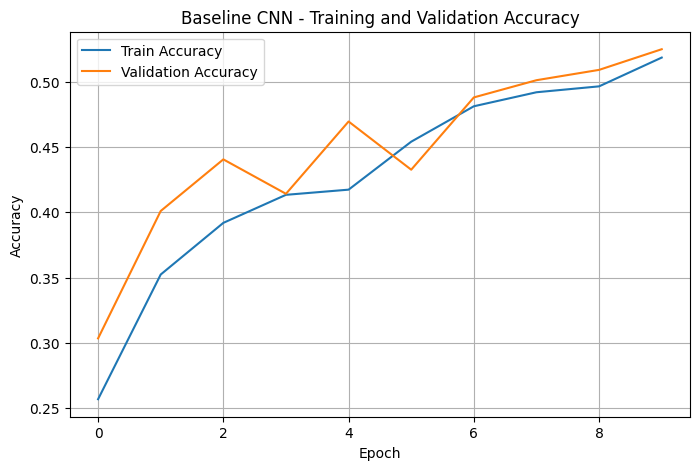

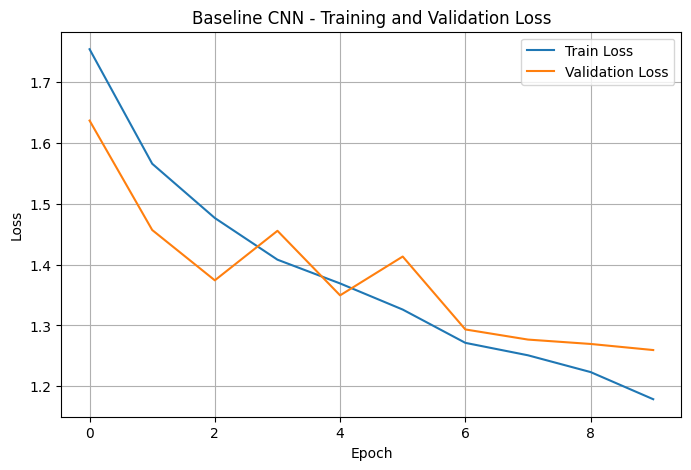

In [100]:
# ============================================================
# 27. VISUALISASI HASIL TRAINING BASELINE CNN
# ============================================================

plot_training_history(
    history=baseline_history,
    model_name="Baseline CNN"
)

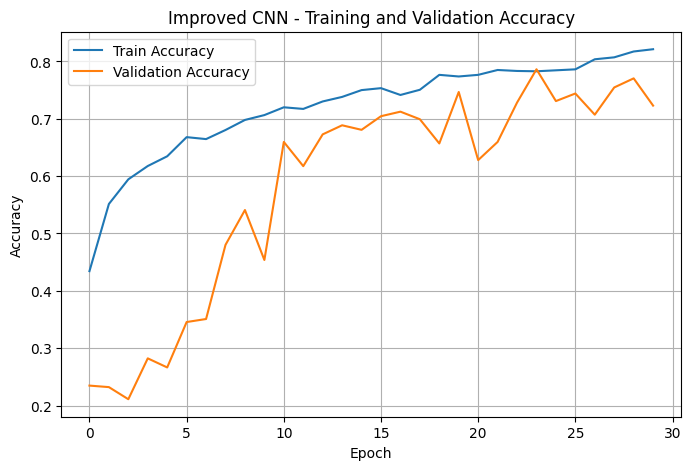

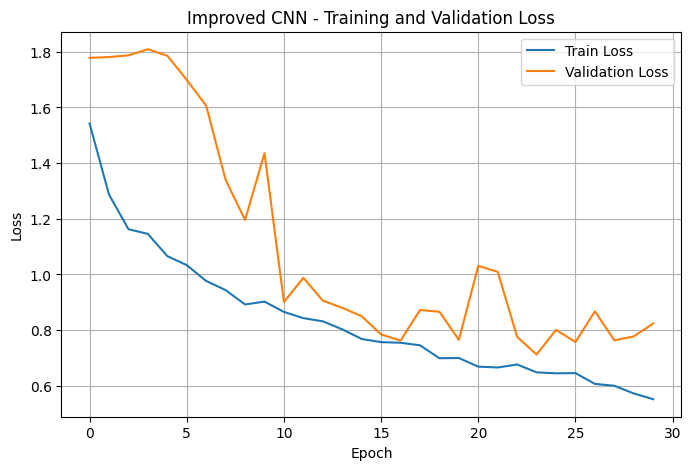

In [101]:
# ============================================================
# 28. VISUALISASI HASIL TRAINING IMPROVED CNN
# ============================================================

plot_training_history(
    history=improved_history,
    model_name="Improved CNN"
)

In [ ]:
# FUNCTION UNTUK EVALUASI MODEL


def evaluate_model(model, model_name):
    print(f"Evaluating {model_name}...")
    
    results = model.evaluate(test_ds, verbose=1)
    
    test_loss = results[0]
    test_accuracy = results[1]
    test_precision = results[2]
    test_recall = results[3]
    
    print(f"\n{model_name} Test Results")
    print("Test Loss     :", test_loss)
    print("Test Accuracy :", test_accuracy)
    print("Test Precision:", test_precision)
    print("Test Recall   :", test_recall)
    
    return {
        "model_name": model_name,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
        "test_precision": test_precision,
        "test_recall": test_recall
    }

## Data Testing

In [ ]:
# EVALUASI BASELINE CNN


baseline_results = evaluate_model(
    model=baseline_model,
    model_name="Baseline CNN"
)

Evaluating Baseline CNN...
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 177ms/step - accuracy: 0.5474 - loss: 1.1918 - precision: 0.7394 - recall: 0.3658

Baseline CNN Test Results
Test Loss     : 1.191788673400879
Test Accuracy : 0.5473684072494507
Test Precision: 0.7393617033958435
Test Recall   : 0.3657894730567932


In [ ]:
# EVALUASI IMPROVED CNN


improved_results = evaluate_model(
    model=improved_model,
    model_name="Improved CNN"
)

Evaluating Improved CNN...
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 245ms/step - accuracy: 0.8026 - loss: 0.5865 - precision: 0.8715 - recall: 0.7316

Improved CNN Test Results
Test Loss     : 0.5864806175231934
Test Accuracy : 0.8026315569877625
Test Precision: 0.8714733719825745
Test Recall   : 0.7315789461135864


In [ ]:
#  FUNCTION UNTUK MENDAPATKAN PREDICTION

def get_predictions(model, dataset):
    y_true = []
    y_pred = []
    
    for images, labels in dataset:
        predictions = model.predict(images, verbose=0)
        
        predicted_classes = np.argmax(predictions, axis=1)
        true_classes = np.argmax(labels.numpy(), axis=1)
        
        y_pred.extend(predicted_classes)
        y_true.extend(true_classes)
    
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    return y_true, y_pred

In [ ]:

#. PREDICTION BASELINE CNN

baseline_y_true, baseline_y_pred = get_predictions(
    model=baseline_model,
    dataset=test_ds
)

In [ ]:
# PREDICTION IMPROVED CNN


improved_y_true, improved_y_pred = get_predictions(
    model=improved_model,
    dataset=test_ds
)

In [ ]:
# CLASSIFICATION REPORT BASELINE CNN

print("Classification Report - Baseline CNN")
print(classification_report(
    baseline_y_true,
    baseline_y_pred,
    target_names=class_names
))

Classification Report - Baseline CNN
              precision    recall  f1-score   support

   cardboard       0.80      0.62      0.70        60
       glass       0.62      0.33      0.43        76
       metal       0.48      0.69      0.57        62
       paper       0.63      0.49      0.55        89
     plastic       0.47      0.56      0.51        73
       trash       0.38      0.90      0.54        20

    accuracy                           0.55       380
   macro avg       0.56      0.60      0.55       380
weighted avg       0.59      0.55      0.55       380



Hasil classification report menunjukkan bahwa model `Baseline CNN` memperoleh accuracy sebesar `0.55` pada test set. Artinya, dari total 380 gambar test, sekitar 55% gambar berhasil diklasifikasikan dengan benar. Hasil ini menunjukkan bahwa model baseline sudah mampu belajar sebagian pola dari dataset, tetapi performanya masih belum cukup kuat untuk membedakan semua kelas dengan baik.

Pada kelas `cardboard`, model memperoleh precision sebesar `0.80`, recall sebesar `0.62`, dan f1-score sebesar `0.70`. Precision yang cukup tinggi menunjukkan bahwa ketika model memprediksi gambar sebagai cardboard, prediksi tersebut cukup sering benar. Namun, recall 0.62 menunjukkan bahwa masih ada beberapa gambar cardboard yang salah diklasifikasikan ke kelas lain.

Pada kelas `glass`, model memperoleh precision sebesar `0.62`, recall sebesar `0.33`, dan f1-score sebesar `0.43`. Recall yang rendah menunjukkan bahwa model masih kesulitan mengenali gambar glass. Banyak gambar glass kemungkinan salah diprediksi sebagai kelas lain seperti metal, plastic, atau trash. Ini menjadi salah satu alasan mengapa pada model improved dilakukan penyesuaian class weight untuk kelas glass.

Pada kelas `metal`, model memperoleh precision sebesar `0.48`, recall sebesar `0.69`, dan f1-score sebesar `0.57`. Recall yang cukup tinggi menunjukkan bahwa model cukup sering berhasil menemukan gambar metal asli. Namun, precision yang rendah menunjukkan bahwa banyak prediksi metal ternyata berasal dari kelas lain. Artinya, model cenderung terlalu sering memprediksi gambar sebagai metal.

Pada kelas `paper`, model memperoleh precision sebesar `0.63`, recall sebesar `0.49`, dan f1-score sebesar `0.55`. Nilai ini menunjukkan bahwa model masih cukup kesulitan membedakan paper dari kelas lain, terutama karena beberapa objek paper dapat terlihat mirip dengan cardboard atau trash.

Pada kelas `plastic`, model memperoleh precision sebesar `0.47`, recall sebesar `0.56`, dan f1-score sebesar `0.51`. Hasil ini menunjukkan bahwa performa model pada kelas plastic masih sedang. Model dapat mengenali sebagian gambar plastic, tetapi masih banyak kesalahan prediksi, kemungkinan karena plastic memiliki bentuk dan warna yang bervariasi serta bisa terlihat mirip dengan glass atau trash.

Pada kelas `trash`, model memperoleh precision sebesar `0.38`, recall sebesar `0.90`, dan f1-score sebesar `0.54`. Recall yang sangat tinggi menunjukkan bahwa sebagian besar gambar trash berhasil dikenali. Namun, precision yang sangat rendah menunjukkan bahwa model terlalu sering memprediksi gambar sebagai trash, sehingga banyak prediksi trash sebenarnya berasal dari kelas lain. Ini berarti model terlalu sensitif terhadap kelas trash.

Nilai macro average precision adalah `0.56`, macro average recall adalah `0.60`, dan macro average f1-score adalah `0.55`. Macro average menghitung rata-rata semua kelas secara seimbang, sehingga nilai ini menunjukkan bahwa performa antar kelas masih belum stabil. Beberapa kelas seperti cardboard dan trash memiliki recall cukup baik, tetapi kelas glass masih sangat lemah.

Weighted average precision adalah `0.59`, weighted average recall adalah `0.55`, dan weighted average f1-score adalah `0.55`. Weighted average memperhitungkan jumlah data pada setiap kelas. Nilai weighted f1-score yang hanya 0.55 menunjukkan bahwa performa keseluruhan model baseline masih terbatas.

Secara keseluruhan, Baseline CNN memberikan performa awal yang cukup sebagai model pembanding, tetapi belum optimal. Accuracy 55% dan weighted f1-score 0.55 menunjukkan bahwa model masih kesulitan membedakan beberapa kelas, terutama `glass`, `paper`, dan `plastic`. Hasil ini juga menunjukkan bahwa arsitektur baseline yang sederhana belum cukup kuat untuk menangkap pola visual kompleks pada dataset sampah. Oleh karena itu, model improved diperlukan untuk meningkatkan performa, terutama dengan tambahan Batch Normalization, GlobalAveragePooling2D, convolution block yang lebih dalam, dan custom class weight untuk memperbaiki recall kelas glass.

In [ ]:

#. CLASSIFICATION REPORT IMPROVED CNN


print("Classification Report - Improved CNN")
print(classification_report(
    improved_y_true,
    improved_y_pred,
    target_names=class_names
))

Classification Report - Improved CNN
              precision    recall  f1-score   support

   cardboard       0.94      0.77      0.84        60
       glass       0.75      0.74      0.74        76
       metal       0.74      0.77      0.76        62
       paper       0.85      0.93      0.89        89
     plastic       0.75      0.79      0.77        73
       trash       0.88      0.70      0.78        20

    accuracy                           0.80       380
   macro avg       0.82      0.78      0.80       380
weighted avg       0.81      0.80      0.80       380



Hasil classification report menunjukkan bahwa model `Improved CNN` memiliki performa yang cukup baik pada test set. Model mencapai accuracy sebesar `0.80`, artinya sekitar 80% dari total 380 gambar test berhasil diklasifikasikan dengan benar.

Secara umum, nilai precision, recall, dan f1-score pada sebagian besar kelas sudah cukup seimbang. Hal ini menunjukkan bahwa model tidak hanya bagus pada satu kelas tertentu, tetapi cukup mampu mengenali beberapa jenis sampah dengan performa yang relatif stabil.

Pada kelas `cardboard`, model memperoleh precision sebesar `0.94`, recall sebesar `0.77`, dan f1-score sebesar `0.84`. Precision yang tinggi menunjukkan bahwa ketika model memprediksi sebuah gambar sebagai cardboard, prediksi tersebut sangat sering benar. Namun, recall 0.77 menunjukkan bahwa masih ada beberapa gambar cardboard yang salah diklasifikasikan ke kelas lain.

Pada kelas `glass`, model memperoleh precision sebesar `0.75`, recall sebesar `0.74`, dan f1-score sebesar `0.74`. Hasil ini cukup penting karena sebelumnya kelas glass memiliki recall yang rendah. Dengan recall 0.74, model sudah jauh lebih baik dalam mengenali gambar glass. Hal ini menunjukkan bahwa penggunaan custom class weight untuk kelas glass membantu model memberikan perhatian lebih besar terhadap kelas tersebut.

Pada kelas `metal`, model memperoleh precision sebesar `0.74`, recall sebesar `0.77`, dan f1-score sebesar `0.76`. Nilai ini menunjukkan bahwa performa model pada kelas metal cukup seimbang. Model cukup mampu mengenali metal, meskipun masih ada kemungkinan tertukar dengan kelas lain yang memiliki karakter visual mirip, seperti glass atau plastic.

Pada kelas `paper`, model memperoleh hasil terbaik dengan precision sebesar `0.85`, recall sebesar `0.93`, dan f1-score sebesar `0.89`. Recall yang sangat tinggi menunjukkan bahwa sebagian besar gambar paper berhasil dikenali dengan benar. Hal ini kemungkinan karena jumlah data paper cukup banyak dan karakter visualnya lebih mudah dibedakan dibanding beberapa kelas lain.

Pada kelas `plastic`, model memperoleh precision sebesar `0.75`, recall sebesar `0.79`, dan f1-score sebesar `0.77`. Hasil ini menunjukkan bahwa model cukup baik dalam mengenali plastic, tetapi masih ada kemungkinan plastic tertukar dengan glass atau trash karena secara visual beberapa objek plastik dan kaca dapat terlihat mirip, terutama pada objek transparan.

Pada kelas `trash`, model memperoleh precision sebesar `0.88`, recall sebesar `0.70`, dan f1-score sebesar `0.78`. Precision yang tinggi menunjukkan bahwa ketika model memprediksi gambar sebagai trash, prediksi tersebut cukup sering benar. Namun, recall 0.70 menunjukkan bahwa masih ada beberapa gambar trash yang belum berhasil dikenali sebagai trash. Hal ini wajar karena kelas trash memiliki jumlah data paling sedikit, yaitu hanya 20 gambar pada test set.

Nilai macro average precision adalah `0.82`, macro average recall adalah `0.78`, dan macro average f1-score adalah `0.80`. Macro average menghitung rata-rata performa setiap kelas secara seimbang tanpa memperhatikan jumlah data per kelas. Nilai ini menunjukkan bahwa model memiliki performa yang cukup merata antar kelas.

Weighted average precision adalah `0.81`, weighted average recall adalah `0.80`, dan weighted average f1-score adalah `0.80`. Weighted average memperhitungkan jumlah data pada setiap kelas. Karena nilainya mirip dengan macro average, ini menunjukkan bahwa performa model cukup stabil meskipun dataset memiliki class imbalance.

Secara keseluruhan, Improved CNN menunjukkan hasil yang baik dengan accuracy 80% dan weighted f1-score 0.80. Model berhasil meningkatkan performa dibanding baseline, terutama pada kemampuan mengenali kelas glass yang sebelumnya memiliki recall rendah. Meskipun masih ada beberapa kelas yang dapat ditingkatkan, seperti trash dan cardboard dari sisi recall, hasil ini menunjukkan bahwa arsitektur Improved CNN, data augmentation, Batch Normalization, GlobalAveragePooling2D, dan custom class weight memberikan pengaruh positif terhadap performa model.

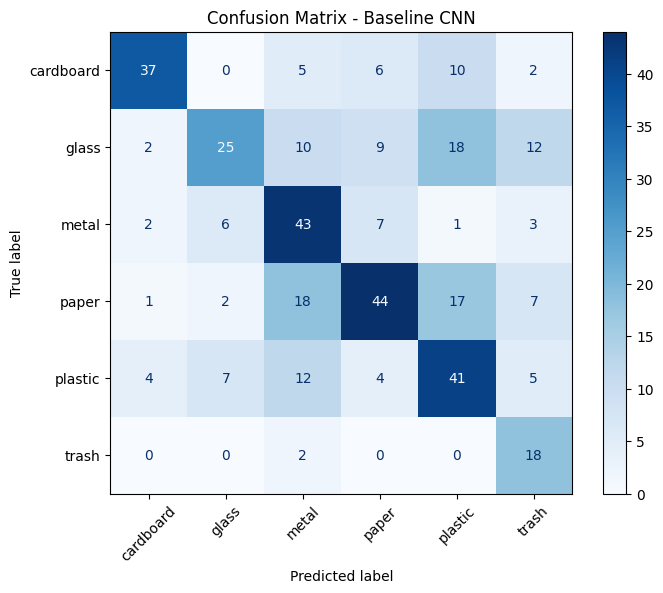

In [ ]:
# CONFUSION MATRIX BASELINE CNN


baseline_cm = confusion_matrix(
    baseline_y_true,
    baseline_y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=baseline_cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title("Confusion Matrix - Baseline CNN")
plt.show()

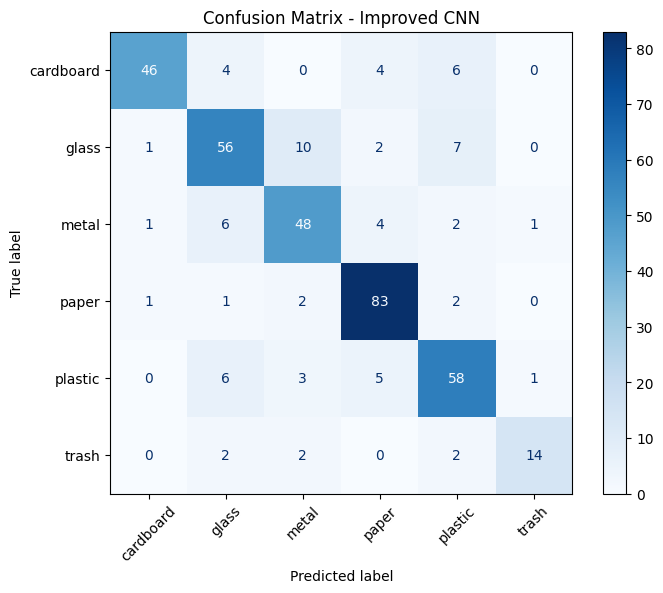

In [ ]:
# CONFUSION MATRIX IMPROVED CNN

improved_cm = confusion_matrix(
    improved_y_true,
    improved_y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=improved_cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title("Confusion Matrix - Improved CNN")
plt.show()

In [ ]:
#  MEMBANDINGKAN HASIL KEDUA MODEL


comparison_df = pd.DataFrame([
    {
        "Model": baseline_results["model_name"],
        "Test Loss": baseline_results["test_loss"],
        "Test Accuracy": baseline_results["test_accuracy"],
        "Test Precision": baseline_results["test_precision"],
        "Test Recall": baseline_results["test_recall"],
        "Training Time (seconds)": baseline_training_time
    },
    {
        "Model": improved_results["model_name"],
        "Test Loss": improved_results["test_loss"],
        "Test Accuracy": improved_results["test_accuracy"],
        "Test Precision": improved_results["test_precision"],
        "Test Recall": improved_results["test_recall"],
        "Training Time (seconds)": improved_training_time
    }
])

comparison_df

,Model,Test Loss,Test Accuracy,Test Precision,Test Recall,Training Time (seconds)
0,Baseline CNN,1.191789,0.547368,0.739362,0.365789,371.333068
1,Improved CNN,0.586481,0.802632,0.871473,0.731579,11892.249425


Berdasarkan hasil evaluasi, terdapat perbedaan performa yang cukup besar antara `Baseline CNN` dan `Improved CNN`. Model Baseline CNN memperoleh test accuracy sebesar `0.5474` atau sekitar `54.74%`, sedangkan Improved CNN memperoleh test accuracy sebesar `0.8026` atau sekitar `80.26%`. Artinya, Improved CNN mampu mengklasifikasikan gambar test dengan jauh lebih baik dibandingkan Baseline CNN.

Dari sisi test loss, Baseline CNN memiliki loss sebesar `1.1918`, sedangkan Improved CNN memiliki loss sebesar `0.5865`. Nilai loss yang lebih rendah pada Improved CNN menunjukkan bahwa model ini tidak hanya menghasilkan prediksi yang lebih banyak benar, tetapi juga lebih yakin dan lebih stabil dalam melakukan klasifikasi. Dengan kata lain, Improved CNN memiliki error prediksi yang lebih kecil dibandingkan Baseline CNN.

Pada metric precision, Baseline CNN memperoleh nilai `0.7394`, sedangkan Improved CNN memperoleh nilai `0.8715`. Precision yang lebih tinggi menunjukkan bahwa ketika Improved CNN memprediksi suatu gambar ke dalam kelas tertentu, prediksi tersebut lebih sering benar dibandingkan Baseline CNN. Ini berarti Improved CNN lebih sedikit menghasilkan prediksi yang salah untuk kelas yang dipilih.

Perbedaan paling penting terlihat pada recall. Baseline CNN hanya memperoleh recall sebesar `0.3658`, sedangkan Improved CNN memperoleh recall sebesar `0.7316`. Recall yang rendah pada Baseline CNN menunjukkan bahwa model masih banyak gagal menangkap data asli dari setiap kelas. Sebaliknya, recall Improved CNN yang jauh lebih tinggi menunjukkan bahwa model lebih mampu mengenali gambar-gambar dari kelas sebenarnya. Ini sangat penting karena dataset memiliki class imbalance dan sebelumnya kelas seperti `glass` memiliki recall yang rendah.

Peningkatan performa Improved CNN terjadi karena arsitekturnya lebih kuat dibandingkan Baseline CNN. Baseline CNN hanya menggunakan convolution layer sederhana, MaxPooling, Flatten, Dense, dan Dropout. Model ini cukup baik sebagai model awal, tetapi masih terbatas dalam menangkap pola visual yang kompleks. Selain itu, penggunaan `Flatten` dapat menghasilkan jumlah parameter yang besar sehingga model lebih mudah overfitting dan kurang stabil.

Improved CNN memiliki beberapa peningkatan penting. Pertama, model menggunakan convolution block yang lebih dalam dengan jumlah filter sampai 256. Hal ini membuat model mampu mempelajari fitur visual yang lebih kompleks, mulai dari edge dan tekstur sederhana pada layer awal, sampai bentuk dan pola objek yang lebih spesifik pada layer yang lebih dalam. Kedua, Improved CNN menggunakan `BatchNormalization` setelah convolution layer. Batch Normalization membantu proses training menjadi lebih stabil dan membuat model lebih mudah belajar. Ketiga, model menggunakan `GlobalAveragePooling2D` sebagai pengganti `Flatten`. GlobalAveragePooling2D membuat jumlah parameter lebih terkontrol sehingga risiko overfitting dapat dikurangi.

Selain perubahan arsitektur, Improved CNN juga menggunakan custom class weight untuk membantu memperbaiki performa kelas `glass`. Pada hasil sebelumnya, kelas `glass` memiliki recall yang rendah, sehingga model sering gagal mengenali gambar kaca dan salah mengklasifikasikannya sebagai kelas lain seperti `metal`, `plastic`, atau `trash`. Dengan menaikkan bobot kelas `glass`, model diberi penalti loss yang lebih besar ketika salah memprediksi gambar glass. Akibatnya, model menjadi lebih memperhatikan karakteristik visual kelas glass selama training.

Awalnya, Improved CNN sempat menghasilkan performa validation yang rendah pada epoch awal. Namun, setelah training berjalan lebih lama, model mulai belajar lebih stabil. Hal ini menunjukkan bahwa model yang lebih kompleks membutuhkan waktu lebih banyak untuk menyesuaikan bobotnya. Setelah custom class weight diterapkan dan callback diatur agar memantau `val_accuracy`, model tidak berhenti terlalu cepat dan akhirnya mampu mencapai performa yang jauh lebih baik.

Dari sisi waktu training, Improved CNN membutuhkan waktu jauh lebih lama, yaitu sekitar `11892.25` detik, sedangkan Baseline CNN hanya membutuhkan sekitar `371.33` detik. Hal ini wajar karena Improved CNN memiliki arsitektur yang lebih kompleks, jumlah layer lebih banyak, dan dilatih lebih lama. Namun, peningkatan waktu training tersebut sebanding dengan peningkatan performa yang diperoleh.

Secara keseluruhan, Improved CNN memberikan hasil yang jauh lebih baik dibandingkan Baseline CNN. Test accuracy meningkat dari `54.74%` menjadi `80.26%`, precision meningkat dari `73.94%` menjadi `87.15%`, dan recall meningkat dari `36.58%` menjadi `73.16%`. Peningkatan recall yang besar menunjukkan bahwa Improved CNN lebih mampu mengenali data dari berbagai kelas, bukan hanya memprediksi kelas tertentu secara hati-hati. Oleh karena itu, Improved CNN dapat dianggap sebagai model yang lebih baik untuk final project ini.


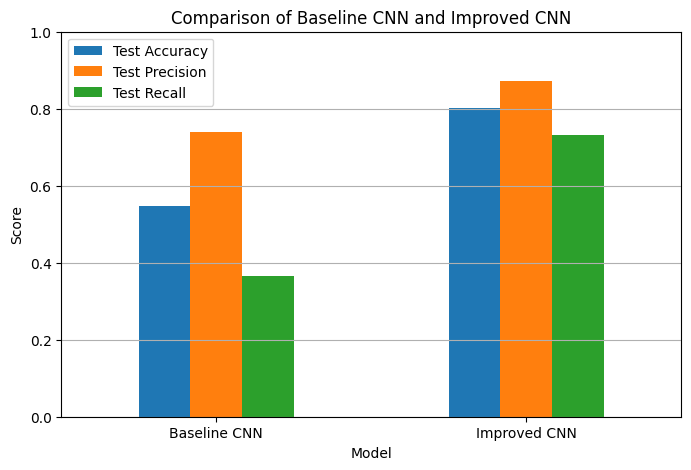

In [ ]:
# 41. VISUALISASI PERBANDINGAN METRIC MODEL

metrics_to_plot = [
    "Test Accuracy",
    "Test Precision",
    "Test Recall"
]

comparison_df_rounded.set_index("Model")[metrics_to_plot].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Comparison of Baseline CNN and Improved CNN")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

In [ ]:
#  MENENTUKAN MODEL TERBAIK BERDASARKAN TEST ACCURACY


best_model_row = comparison_df.loc[
    comparison_df["Test Accuracy"].idxmax()
]

print("Best Model Based on Test Accuracy:")
print(best_model_row)

Best Model Based on Test Accuracy:
Model                      Improved CNN
Test Loss                      0.586481
Test Accuracy                  0.802632
Test Precision                 0.871473
Test Recall                    0.731579
Training Time (seconds)    11892.249425
Name: 1, dtype: object


In [117]:
# ============================================================
# SAVE KEDUA MODEL
# ============================================================

baseline_model.save("final_baseline_cnn.keras")
improved_model.save("final_improved_cnn.keras")

print("Baseline CNN saved as final_baseline_cnn.keras")
print("Improved CNN saved as final_improved_cnn.keras")

Baseline CNN saved as final_baseline_cnn.keras
Improved CNN saved as final_improved_cnn.keras


## Grad-CAM

### Import dan Folder Output

In [204]:
# ============================================================
# 44. IMPORT LIBRARY DAN FOLDER OUTPUT GRAD-CAM
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path

gradcam_output_dir = Path("gradcam_outputs")
gradcam_output_dir.mkdir(exist_ok=True)

wrong_output_dir = gradcam_output_dir / "wrong_predictions"
wrong_output_dir.mkdir(exist_ok=True)

glass_output_dir = gradcam_output_dir / "glass_predictions"
glass_output_dir.mkdir(exist_ok=True)

high_conf_output_dir = gradcam_output_dir / "high_confidence_wrong_predictions"
high_conf_output_dir.mkdir(exist_ok=True)

print("Folder Grad-CAM berhasil dibuat:")
print(gradcam_output_dir)

Folder Grad-CAM berhasil dibuat:
gradcam_outputs


### Load Model dan Cek Layer

In [205]:
# ============================================================
# 45. PASTIKAN MODEL SIAP UNTUK GRAD-CAM
# ============================================================

dummy_input = tf.zeros((1, 224, 224, 3))
_ = improved_model(dummy_input, training=False)

print("Model sudah siap untuk Grad-CAM.")

print("\nDaftar layer pada improved_model:")
for layer in improved_model.layers:
    print(layer.name)

Model sudah siap untuk Grad-CAM.

Daftar layer pada improved_model:
data_augmentation
conv2d_15
batch_normalization_12
max_pooling2d_21
conv2d_16
batch_normalization_13
max_pooling2d_22
conv2d_17
batch_normalization_14
max_pooling2d_23
improved_last_conv_layer
batch_normalization_15
max_pooling2d_24
global_average_pooling2d_3
dense_12
dropout_6
dense_13


### Semua Function Grad-CAM

In [206]:
# ============================================================
# 46. FUNCTION GRAD-CAM
# ============================================================

def load_image_for_gradcam(image_path):
    image = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image


def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    """
    Membuat Grad-CAM heatmap dengan cara melewatkan input manual
    dari layer ke layer agar gradient tetap tersambung.
    """

    with tf.GradientTape() as tape:
        x = img_array
        conv_outputs = None

        for layer in model.layers:
            try:
                x = layer(x, training=False)
            except TypeError:
                x = layer(x)

            if layer.name == last_conv_layer_name:
                conv_outputs = x
                tape.watch(conv_outputs)

        predictions = x

        if pred_index is None:
            pred_index = tf.argmax(predictions[0])

        class_channel = predictions[:, pred_index]

    if conv_outputs is None:
        raise ValueError(
            f"Layer '{last_conv_layer_name}' tidak ditemukan. "
            "Cek nama layer model."
        )

    grads = tape.gradient(class_channel, conv_outputs)

    if grads is None:
        raise ValueError(
            "Gradient bernilai None. Pastikan model sudah dipanggil "
            "dan last_conv_layer_name benar."
        )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    max_value = tf.reduce_max(heatmap)

    if max_value == 0:
        return heatmap.numpy()

    heatmap = heatmap / max_value

    return heatmap.numpy()


def display_gradcam(
    image_path,
    model,
    last_conv_layer_name,
    true_label=None,
    save_path=None,
    alpha=0.4
):
    image = load_image_for_gradcam(image_path)
    img_array = tf.expand_dims(image, axis=0)

    predictions = model(img_array, training=False).numpy()
    predicted_index = np.argmax(predictions[0])
    predicted_label = index_to_class[predicted_index]
    confidence = predictions[0][predicted_index]

    heatmap = make_gradcam_heatmap(
        img_array=img_array,
        model=model,
        last_conv_layer_name=last_conv_layer_name,
        pred_index=predicted_index
    )

    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        IMG_SIZE
    )

    heatmap_resized = tf.squeeze(heatmap_resized).numpy()

    fig = plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(image)
    plt.title(f"Original Image\nTrue Label: {true_label}")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title("Grad-CAM Heatmap")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(image)
    plt.imshow(heatmap_resized, cmap="jet", alpha=alpha)
    plt.title(
        f"Overlay\nPredicted: {predicted_label}\nConfidence: {confidence:.2f}"
    )
    plt.axis("off")

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=150,
            bbox_inches="tight"
        )

    plt.show()
    plt.close(fig)

    print("True Label      :", true_label)
    print("Predicted Label :", predicted_label)
    print("Confidence      :", round(float(confidence), 4))

    return {
        "image_path": image_path,
        "true_label": true_label,
        "predicted_label": predicted_label,
        "confidence": float(confidence),
        "save_path": str(save_path) if save_path is not None else None
    }

### Buat DataFrame Prediksi Test Set

In [207]:
# ============================================================
# 47. MEMBUAT DATAFRAME PREDIKSI TEST SET
# ============================================================

test_predictions = []

for idx, row in test_df.iterrows():
    image = load_image_for_gradcam(row["image_path"])
    img_array = tf.expand_dims(image, axis=0)

    predictions = improved_model(img_array, training=False).numpy()
    predicted_index = np.argmax(predictions[0])
    predicted_label = index_to_class[predicted_index]
    confidence = predictions[0][predicted_index]

    test_predictions.append({
        "image_path": row["image_path"],
        "true_label": row["label"],
        "predicted_label": predicted_label,
        "confidence": float(confidence),
        "is_correct": row["label"] == predicted_label
    })

pred_df = pd.DataFrame(test_predictions)

total_test = len(pred_df)
correct_count = pred_df["is_correct"].sum()
wrong_count = total_test - correct_count

print("Total test data       :", total_test)
print("Jumlah prediksi benar :", correct_count)
print("Jumlah prediksi salah :", wrong_count)
print("Accuracy manual       :", correct_count / total_test)

pred_df.head()

Total test data       : 380
Jumlah prediksi benar : 305
Jumlah prediksi salah : 75
Accuracy manual       : 0.8026315789473685


,image_path,true_label,predicted_label,confidence,is_correct
0,trash_images\metal\metal_084.jpg,metal,metal,0.932273,True
1,trash_images\plastic\plastic_381.jpg,plastic,plastic,0.536136,True
2,trash_images\cardboard\cardboard_157.jpg,cardboard,cardboard,0.994268,True
3,trash_images\glass\glass_094.jpg,glass,glass,0.577125,True
4,trash_images\glass\glass_337.jpg,glass,glass,0.742184,True


### Save DataFrame Prediksi

In [208]:
# ============================================================
# 48. SAVE DATAFRAME PREDIKSI TEST SET
# ============================================================

pred_csv_path = gradcam_output_dir / "test_predictions.csv"

pred_df.to_csv(
    pred_csv_path,
    index=False
)

print("File prediksi test berhasil disimpan di:")
print(pred_csv_path)

File prediksi test berhasil disimpan di:
gradcam_outputs\test_predictions.csv


### Grad-CAM Contoh Gambar Test

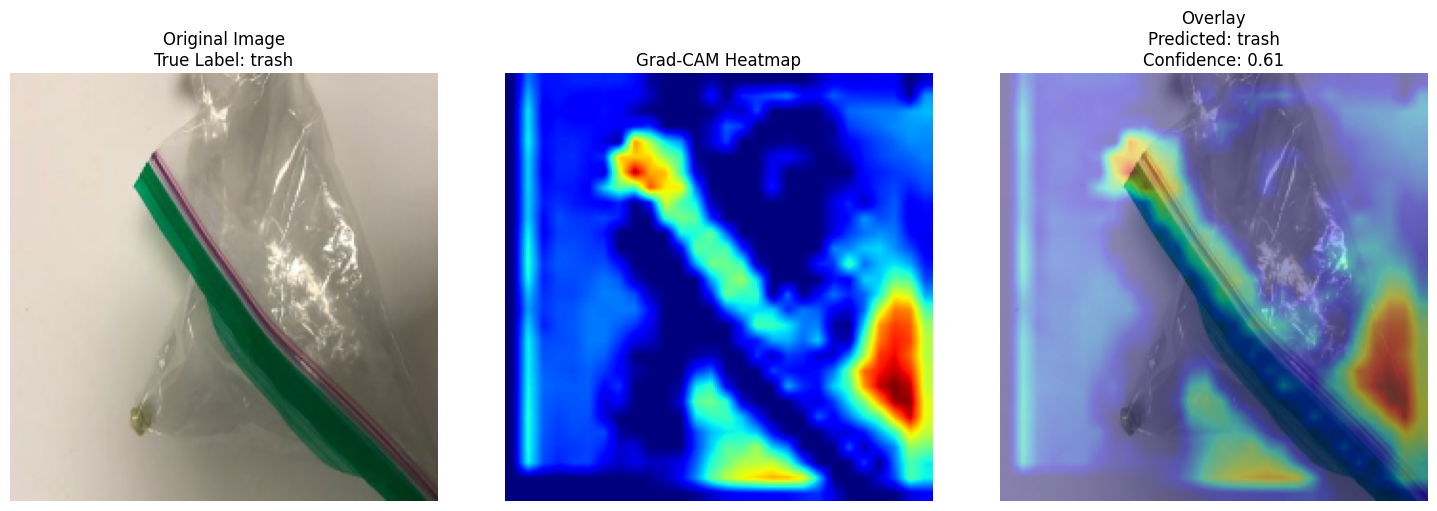

True Label      : trash
Predicted Label : trash
Confidence      : 0.6142


{'image_path': 'trash_images\\trash\\trash_102.jpg',
 'true_label': 'trash',
 'predicted_label': 'trash',
 'confidence': 0.6141729354858398,
 'save_path': None}

In [209]:
# ============================================================
# 49. GRAD-CAM UNTUK SATU GAMBAR TEST
# ============================================================

sample_row = test_df.sample(
    n=1,
    random_state=SEED
).iloc[0]

sample_image_path = sample_row["image_path"]
sample_true_label = sample_row["label"]

display_gradcam(
    image_path=sample_image_path,
    model=improved_model,
    last_conv_layer_name="improved_last_conv_layer",
    true_label=sample_true_label,
    alpha=0.4
)

### Grad-CAM Khusus Kelas Glass

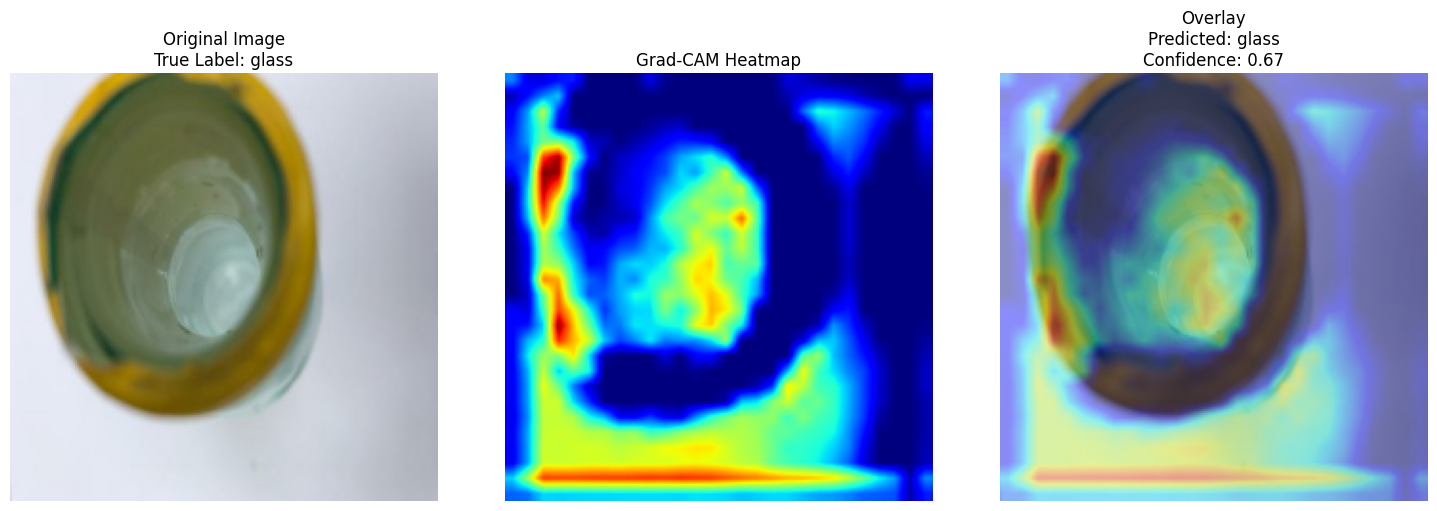

True Label      : glass
Predicted Label : glass
Confidence      : 0.6661
Saved to: gradcam_outputs\glass_predictions\glass_gradcam_1.png
------------------------------------------------------------


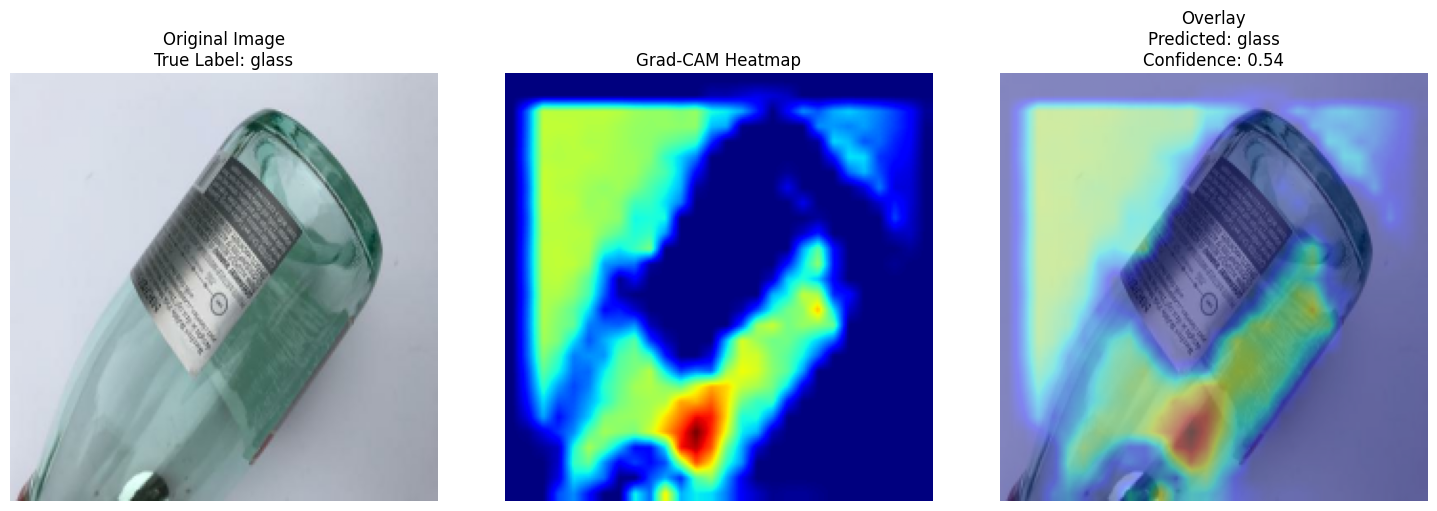

True Label      : glass
Predicted Label : glass
Confidence      : 0.5366
Saved to: gradcam_outputs\glass_predictions\glass_gradcam_2.png
------------------------------------------------------------


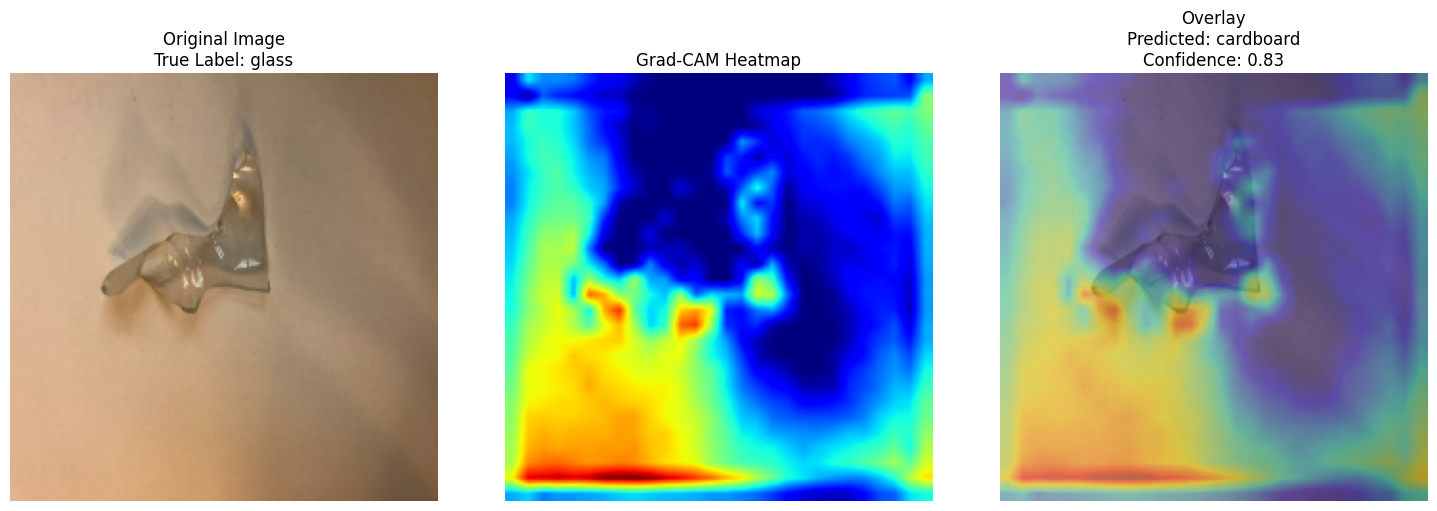

True Label      : glass
Predicted Label : cardboard
Confidence      : 0.8266
Saved to: gradcam_outputs\glass_predictions\glass_gradcam_3.png
------------------------------------------------------------


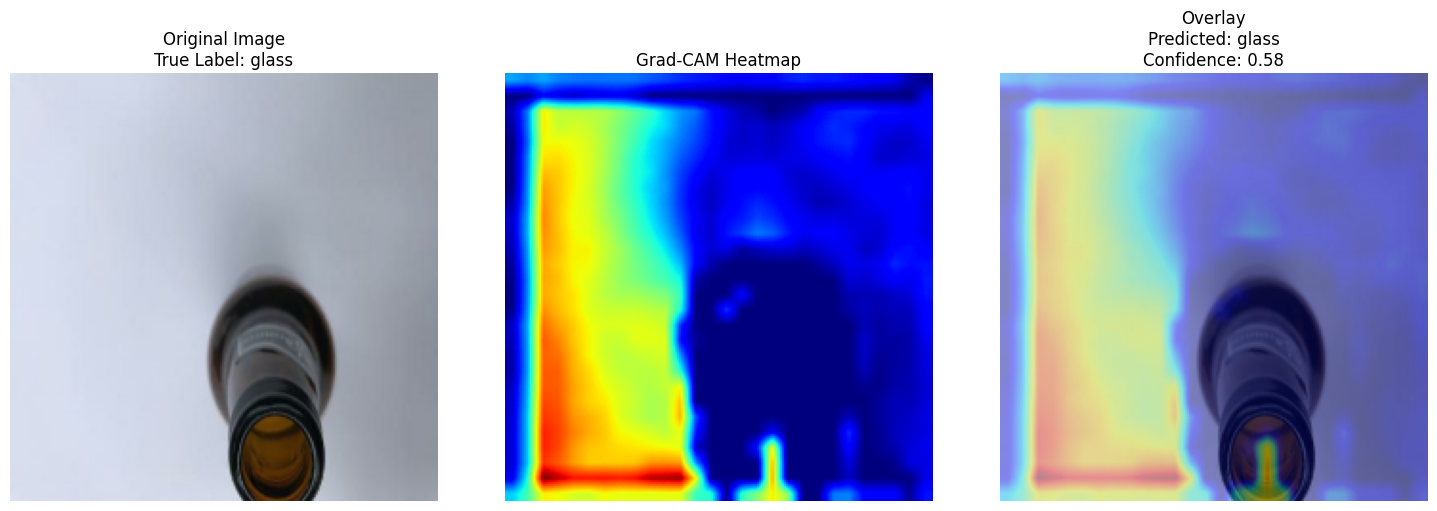

True Label      : glass
Predicted Label : glass
Confidence      : 0.5771
Saved to: gradcam_outputs\glass_predictions\glass_gradcam_4.png
------------------------------------------------------------


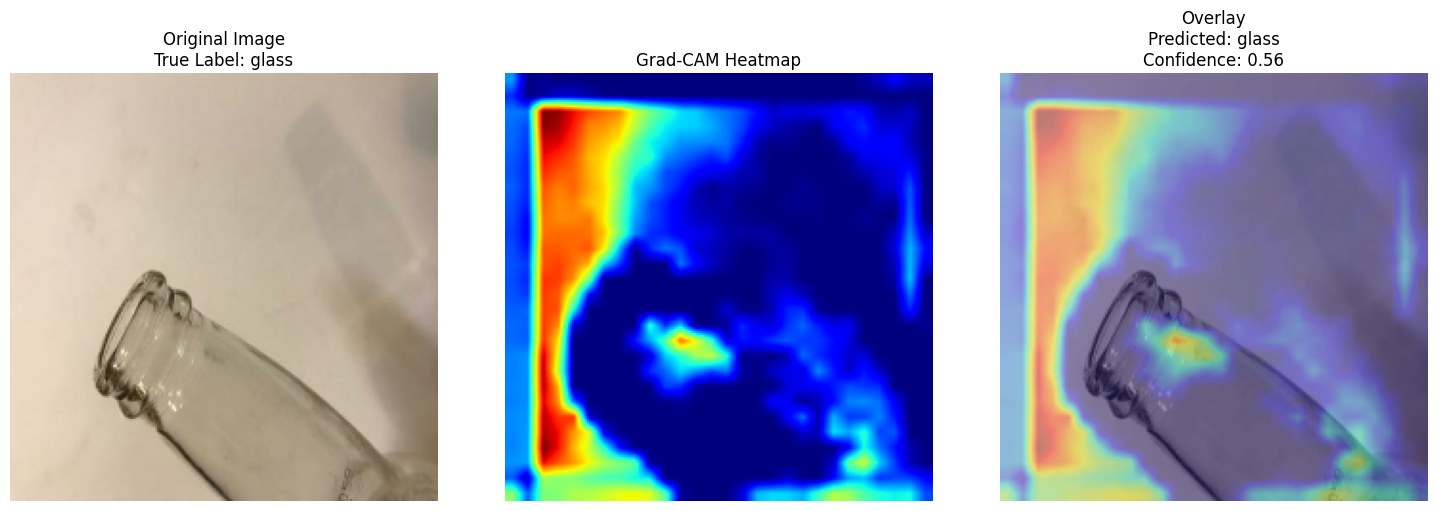

True Label      : glass
Predicted Label : glass
Confidence      : 0.5589
Saved to: gradcam_outputs\glass_predictions\glass_gradcam_5.png
------------------------------------------------------------


In [210]:
# ============================================================
# 50. GRAD-CAM KHUSUS UNTUK KELAS GLASS
# ============================================================

glass_test_df = test_df[test_df["label"] == "glass"]

glass_samples = glass_test_df.sample(
    n=min(5, len(glass_test_df)),
    random_state=SEED
)

glass_gradcam_results = []

for i, row in enumerate(glass_samples.itertuples(), start=1):
    save_path = glass_output_dir / f"glass_gradcam_{i}.png"

    result = display_gradcam(
        image_path=row.image_path,
        model=improved_model,
        last_conv_layer_name="improved_last_conv_layer",
        true_label=row.label,
        save_path=save_path,
        alpha=0.4
    )

    glass_gradcam_results.append(result)

    print("Saved to:", save_path)
    print("-" * 60)

### Grad-CAM Prediksi yang Salah

In [211]:
# ============================================================
# 51. GRAD-CAM UNTUK PREDIKSI YANG SALAH
# ============================================================

wrong_pred_df = pred_df[pred_df["is_correct"] == False].copy()

print("Jumlah prediksi salah:", len(wrong_pred_df))

wrong_samples = wrong_pred_df.sample(
    n=min(5, len(wrong_pred_df)),
    random_state=SEED
)

wrong_gradcam_results = []

for i, row in enumerate(wrong_samples.itertuples(), start=1):
    save_path = wrong_output_dir / f"wrong_gradcam_{i}_true_{row.true_label}_pred_{row.predicted_label}.png"

    result = display_gradcam(
        image_path=row.image_path,
        model=improved_model,
        last_conv_layer_name="improved_last_conv_layer",
        true_label=row.true_label,
        save_path=save_path,
        alpha=0.4
    )

    wrong_gradcam_results.append(result)

    print("Saved to:", save_path)
    print("-" * 60)

Jumlah prediksi salah: 75


True Label      : metal
Predicted Label : paper
Confidence      : 0.6306
Saved to: gradcam_outputs\wrong_predictions\wrong_gradcam_1_true_metal_pred_paper.png
------------------------------------------------------------


True Label      : glass
Predicted Label : metal
Confidence      : 0.3846
Saved to: gradcam_outputs\wrong_predictions\wrong_gradcam_2_true_glass_pred_metal.png
------------------------------------------------------------


True Label      : paper
Predicted Label : plastic
Confidence      : 0.4328
Saved to: gradcam_outputs\wrong_predictions\wrong_gradcam_3_true_paper_pred_plastic.png
------------------------------------------------------------


True Label      : plastic
Predicted Label : paper
Confidence      : 0.4223
Saved to: gradcam_outputs\wrong_predictions\wrong_gradcam_4_true_plastic_pred_paper.png
------------------------------------------------------------


True Label      : paper
Predicted Label : plastic
Confidence      : 0.7137
Saved to: gradcam_outputs\wrong_predictions\wrong_gradcam_5_true_paper_pred_plastic.png
------------------------------------------------------------


### Grad-CAM Salah dengan Confidence Tertinggi

In [212]:
# ============================================================
# 52. GRAD-CAM UNTUK HIGH CONFIDENCE WRONG PREDICTIONS
# ============================================================

high_conf_wrong_df = wrong_pred_df.sort_values(
    by="confidence",
    ascending=False
).head(5)

high_conf_wrong_df

,image_path,true_label,predicted_label,confidence,is_correct
157,trash_images\plastic\plastic_468.jpg,plastic,trash,0.957230,False
304,trash_images\cardboard\cardboard_072.jpg,cardboard,plastic,0.950318,False
96,trash_images\paper\paper_443.jpg,paper,cardboard,0.935183,False
338,trash_images\cardboard\cardboard_033.jpg,cardboard,plastic,0.911369,False
286,trash_images\glass\glass_435.jpg,glass,plastic,0.893424,False


In [213]:
# ============================================================
# 53. SAVE GRAD-CAM HIGH CONFIDENCE WRONG PREDICTIONS
# ============================================================

high_conf_gradcam_results = []

for i, row in enumerate(high_conf_wrong_df.itertuples(), start=1):
    save_path = high_conf_output_dir / (
        f"high_conf_wrong_{i}_true_{row.true_label}_"
        f"pred_{row.predicted_label}_conf_{row.confidence:.2f}.png"
    )

    result = display_gradcam(
        image_path=row.image_path,
        model=improved_model,
        last_conv_layer_name="improved_last_conv_layer",
        true_label=row.true_label,
        save_path=save_path,
        alpha=0.4
    )

    high_conf_gradcam_results.append(result)

    print("Saved to:", save_path)
    print("-" * 60)

True Label      : plastic
Predicted Label : trash
Confidence      : 0.9572
Saved to: gradcam_outputs\high_confidence_wrong_predictions\high_conf_wrong_1_true_plastic_pred_trash_conf_0.96.png
------------------------------------------------------------


True Label      : cardboard
Predicted Label : plastic
Confidence      : 0.9503
Saved to: gradcam_outputs\high_confidence_wrong_predictions\high_conf_wrong_2_true_cardboard_pred_plastic_conf_0.95.png
------------------------------------------------------------


True Label      : paper
Predicted Label : cardboard
Confidence      : 0.9352
Saved to: gradcam_outputs\high_confidence_wrong_predictions\high_conf_wrong_3_true_paper_pred_cardboard_conf_0.94.png
------------------------------------------------------------


True Label      : cardboard
Predicted Label : plastic
Confidence      : 0.9114
Saved to: gradcam_outputs\high_confidence_wrong_predictions\high_conf_wrong_4_true_cardboard_pred_plastic_conf_0.91.png
------------------------------------------------------------


True Label      : glass
Predicted Label : plastic
Confidence      : 0.8934
Saved to: gradcam_outputs\high_confidence_wrong_predictions\high_conf_wrong_5_true_glass_pred_plastic_conf_0.89.png
------------------------------------------------------------


### Save Ringkasan Grad-CAM

In [214]:
# ============================================================
# 54. SAVE RINGKASAN HASIL GRAD-CAM
# ============================================================

wrong_gradcam_df = pd.DataFrame(wrong_gradcam_results)
glass_gradcam_df = pd.DataFrame(glass_gradcam_results)
high_conf_gradcam_df = pd.DataFrame(high_conf_gradcam_results)

wrong_gradcam_df.to_csv(
    gradcam_output_dir / "wrong_gradcam_results.csv",
    index=False
)

glass_gradcam_df.to_csv(
    gradcam_output_dir / "glass_gradcam_results.csv",
    index=False
)

high_conf_gradcam_df.to_csv(
    gradcam_output_dir / "high_conf_wrong_gradcam_results.csv",
    index=False
)

print("Semua ringkasan Grad-CAM berhasil disimpan.")

Semua ringkasan Grad-CAM berhasil disimpan.


## Kesimpulan Attention Map / Grad-CAM

Pada tahap attention map visualization, digunakan metode Grad-CAM untuk melihat area gambar yang paling diperhatikan oleh model `Improved CNN` ketika melakukan prediksi. Grad-CAM membantu menjelaskan keputusan model CNN yang biasanya sulit diinterpretasikan karena bekerja sebagai black-box model. Dengan visualisasi ini, kita dapat melihat apakah model benar-benar memperhatikan objek utama atau justru fokus pada background.

Hasil Grad-CAM menunjukkan bahwa model secara umum sudah mampu memperhatikan area penting pada gambar. Pada beberapa contoh prediksi yang benar, heatmap terlihat berada di sekitar objek utama, seperti bagian botol, plastik, atau objek sampah yang menjadi target klasifikasi. Hal ini menunjukkan bahwa model tidak hanya menebak secara acak, tetapi menggunakan informasi visual dari objek seperti bentuk, tekstur, warna, dan tepi objek untuk menentukan kelas.

Pada contoh gambar dengan true label `trash`, model berhasil memprediksi kelas dengan benar sebagai `trash` dengan confidence sekitar 0.61. Heatmap menunjukkan bahwa model memperhatikan area objek plastik/trash yang cukup dominan pada gambar. Ini berarti keputusan model masih cukup masuk akal karena area yang diperhatikan berhubungan dengan objek utama.

Grad-CAM juga dilakukan secara khusus pada kelas `glass` karena kelas ini sebelumnya memiliki recall yang rendah pada baseline model. Setelah menggunakan Improved CNN dan custom class weight untuk kelas `glass`, beberapa hasil Grad-CAM menunjukkan bahwa model sudah dapat memprediksi gambar glass dengan benar. Confidence pada beberapa gambar glass berada pada kisaran sedang, misalnya sekitar 0.54 sampai 0.67. Hal ini menunjukkan bahwa model sudah lebih mampu mengenali glass, tetapi masih memiliki tingkat ketidakpastian karena karakteristik glass cukup sulit, seperti transparan, reflektif, dan kadang mirip dengan plastic atau metal.

Selain prediksi yang benar, Grad-CAM juga digunakan untuk menganalisis prediksi yang salah. Pada beberapa kasus, model salah memprediksi karena heatmap tidak sepenuhnya fokus pada objek utama. Ada contoh gambar dengan true label `glass`, tetapi diprediksi sebagai `cardboard` dengan confidence yang cukup tinggi. Dari visualisasi heatmap, terlihat bahwa model juga memperhatikan area background, bukan hanya objek glass. Hal ini menunjukkan bahwa background, pencahayaan, ukuran objek yang kecil, atau posisi objek yang kurang jelas masih dapat memengaruhi keputusan model.

Dari proses ini, dapat disimpulkan bahwa Grad-CAM berhasil membantu menjelaskan cara kerja model. Model Improved CNN sudah cukup baik dalam memperhatikan area objek utama pada banyak gambar, terutama pada prediksi yang benar. Namun, hasil Grad-CAM juga menunjukkan bahwa model masih memiliki kelemahan pada gambar yang sulit, terutama gambar dengan objek transparan, background dominan, atau objek yang hanya terlihat sebagian.

Secara keseluruhan, attention map visualization memperkuat hasil evaluasi model. Improved CNN tidak hanya memiliki accuracy dan recall yang lebih baik, tetapi juga menunjukkan pola perhatian visual yang lebih masuk akal. Meskipun demikian, masih ada peluang pengembangan ke depan, seperti menambah data untuk kelas yang sulit, menggunakan transfer learning, melakukan fine-tuning, atau menggunakan preprocessing tambahan agar objek utama lebih jelas dan model tidak terlalu terpengaruh oleh background.